🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1120 22:10:24.090000 73335 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1120 22:10:24.311000 73335 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
SMART VET — GEMMA 4 E2B + SAVSNET/PetEVAL
GPU: Tesla T4 | VRAM: 14.56 GB | BF16: False
Modelo: unsloth/gemma-4-E2B-it | Dataset: ramoncg/tech-challenge-gemma-llm-fine-tuning-dataset | Contexto: 1024
Precisão: o Unsloth selecionará a configuração compatível com a GPU.
Autenticação Hugging Face concluída (token oculto).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado.

[1/8] Carregando SAVSNET/PetEVAL...


README.md:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.48MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (13 outputs left out)


[Orçamento de treino] 1/10 minutos | passo 9/129.

[Orçamento de treino] 2/10 minutos | passo 25/129.

[Orçamento de treino] 3/10 minutos | passo 40/129.

[Orçamento de treino] 4/10 minutos | passo 55/129.

[Orçamento de treino] 5/10 minutos | passo 70/129.

[Orçamento de treino] 6/10 minutos | passo 86/129.

[Orçamento de treino] 7/10 minutos | passo 101/129.

[Orçamento de treino] 8/10 minutos | passo 116/129.

Passagem completa 1/1 em 531.0s | treinamento acumulado: 8.85 min.

Treino encerrado: 8.85 min; passagens completas confirmadas: 1/1; passos parciais na próxima época: 0/129.

Treinamento concluído.
Duração em minutos: 8.88
Orçamento configurado (segundos): 600
Uma passagem completa confirmada por 129 passos de otimização.
Passagens completas: 1 / 1
Passos parciais na próxima passagem: 0 / 129
Duração da passagem (s): [530.98]
Passos de otimização executados: 0.243 passos/s
Métricas do Trainer: {'train_runtime': 530.9905, 'train_samples_per_second': 0.972, 'train_steps_per_se

Filter:   0%|          | 0/144 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma4ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


Training Loss,Validation Loss,Step
0.272728,0.258302,129


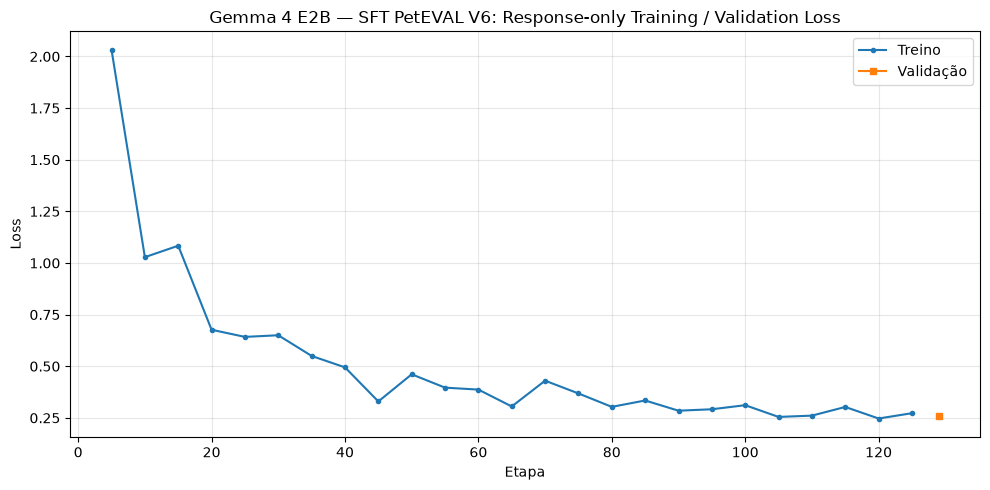

Gráfico salvo em: /content/drive/MyDrive/Gemma/SmartVET_PetEVAL/runs/20261120_221103/training_loss.png


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/Gemma/SmartVET_PetEVAL/runs/20261120_221103/adapter/tokenizer_config.json.


Adaptador LoRA salvo em: /content/drive/MyDrive/Gemma/SmartVET_PetEVAL/runs/20261120_221103/adapter

[4/8] Preparando avaliação generativa... 
Parser NER validado: substrings literais, repetições e rejeição de categorias fora do esquema.
Avaliação icd11_classification: 60 amostras; 0 excluídas por limite de contexto.
Avaliação disease_ner: 60 amostras; 0 excluídas por limite de contexto.
Avaliação annonymisation_ner: 60 amostras; 0 excluídas por limite de contexto.
ICD [1/60] ID=3822586
  Referência: []
  Predição: []
  Rótulos desconhecidos: []
ICD [2/60] ID=1167401
  Referência: ['Certain infectious or parasitic diseases', 'Mental, behavioural or neurodevelopmental disorders', 'Diseases of the visual system']
  Predição: ['Diseases of the immune system']
  Rótulos desconhecidos: []
ICD [3/60] ID=4002521
  Referência: ['Diseases of the respiratory system', 'Diseases of the musculoskeletal system or connective tissue', 'Injury, poisoning or certain other consequences of external causes

7292

In [1]:
# ============================================================================
# SMART VET — GEMMA 4 E2B + SAVSNET/PetEVAL — QUICK TRAIN V6
# GOOGLE COLAB | NOTEBOOK DE UMA ÚNICA CÉLULA
# QLoRA + SFT | ICD-11 MULTILABEL | DISEASE NER | ANONYMISATION NER
#
# FONTE DE DADOS: dataset configurado em DATASET_ID; esquema exigido: sentence/icd_label/disease/annonymisation
# Tarefas:
#   1) classificação multirrótulo de capítulos sindrômicos ICD-11;
#   2) extração de entidades de doenças (Disease NER);
#   3) extração de entidades de anonimização (Anonymisation NER).
#
# Salva/publica somente o adaptador LoRA; GGUF opcional e desativado por padrão.
#
# AVISO METODOLÓGICO IMPORTANTE:
# O repositório SAVSNET/PetEVAL atualmente expõe, no arquivo anexado pelo
# usuário e no Dataset Viewer, somente data/test-00000-of-00001.parquet.
# O artigo original descreve 11.000 train / 1.600 evaluation / 5.000 test,
# com separação por prática veterinária. O split atual do Hub não fornece
# identificador de prática; portanto, o holdout interno NÃO reproduz esse protocolo.
# Este código prioriza splits oficiais quando eles estiverem disponíveis.
# Se encontrar somente 'test', faz um split interno agrupado 85/15 para que
# o experimento possa ser executado, mas NÃO considera o resultado benchmark
# oficial independente: parte do test publicado será usada no treinamento.
# ============================================================================

# ---------------------------------------------------------------------------
# 0. INSTALAÇÃO — executar esta célula em runtime GPU do Google Colab
# ---------------------------------------------------------------------------
%pip install -q -U "unsloth" "transformers>=5.10.1" "trl>=0.16.0" "peft>=0.19.0" datasets accelerate bitsandbytes scikit-learn seqeval matplotlib huggingface_hub

# ---------------------------------------------------------------------------
# 1. IMPORTAÇÕES E CONFIGURAÇÕES GERAIS
# ---------------------------------------------------------------------------
import os
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["UNSLOTH_DISABLE_STATS"] = "1"
os.environ["WANDB_DISABLED"] = "true"

# Importar Unsloth antes de Transformers/TRL, conforme a documentação atual.
import unsloth
from unsloth import FastVisionModel

import ast
import gc
import hashlib
import json
import math
import random
import re
import shutil
import time
import unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone
import getpass as _getpass_module
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from datasets import Dataset, DatasetDict, load_dataset
from huggingface_hub import HfApi, login
from sklearn.model_selection import GroupShuffleSplit
from seqeval.metrics import precision_score as seqeval_precision
from seqeval.metrics import recall_score as seqeval_recall
from seqeval.metrics import f1_score as seqeval_f1
from seqeval.scheme import IOB2
from google.colab import drive, userdata
from trl import SFTTrainer, SFTConfig
from transformers import TrainerCallback
from unsloth.chat_templates import get_chat_template, train_on_responses_only

# =========================== PARÂMETROS DO EXPERIMENTO ======================
SEED = 3407
DATASET_ID = "ramoncg/tech-challenge-gemma-llm-fine-tuning-dataset"
MODEL_ID = "unsloth/gemma-4-E2B-it"

HF_USERNAME = "ramoncg"
ADAPTER_REPO = f"{HF_USERNAME}/tech-challenge-gemma-llm-fine-tuning-adapter-v6"
LIGHT_REPO = f"{HF_USERNAME}/tech-challenge-gemma-llm-fine-tuning-light-v6"

# Contexto. 1024 foi mantido como configuração conservadora para Tesla T4.
# Exemplos que ultrapassarem esse limite serão contabilizados e excluídos,
# em vez de serem truncados silenciosamente (o que quebraria os offsets NER).
MAX_SEQ_LENGTH = 1024
MAX_NEW_TOKENS_ICD = 96
MAX_NEW_TOKENS_NER = 256

# PERFIL RÁPIDO V6 — 516 EXEMPLOS TASK-LABELED / 129 PASSOS / UMA PASSAGEM.
# A V5 executou 72 passos em 318,45 s com 288 exemplos task-labeled.
# A V6 amplia a diversidade para 172 exemplos por tarefa:
# 172 ICD-11 + 172 Disease NER + 172 Anonymisation NER = 516 exemplos.
# Com batch 1 e acumulação 4, são 129 passos de otimização.
# Projeção baseada no ritmo observado da V5: aproximadamente 570 s (9,5 min).
# O limite rígido de treino é 600 s; se a T4 estiver mais lenta, o callback
# interrompe no primeiro limite de passo após 600 s e registra a passagem parcial.
# As narrativas podem aparecer em tarefas diferentes, mas a amostragem é sem
# reposição dentro de cada tarefa. É uma passagem por 516 exemplos task-labeled,
# NÃO uma época sobre todo o corpus PetEVAL.
NUM_EPOCHS = 1.0
EXAMPLES_PER_TASK_PER_EPOCH = 172
EXAMPLES_PER_EPOCH = 516
EVAL_SFT_EXAMPLES_PER_TASK = 48  # mantém 144 exemplos de validação para comparação com V5
MAX_STEPS = 129
MAX_TRAIN_SECONDS = 600
BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 4
LEARNING_RATE = 2e-5
WARMUP_STEPS = 6
EVAL_SAVE_STEPS = 0  # avaliação após o treino; não consome o orçamento de treinamento
LOGGING_STEPS = 5

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 0.3

# Split interno só é usado se o Hub não disponibilizar train/validation.
INTERNAL_VALIDATION_FRACTION = 0.15
GROUP_SPLIT_CANDIDATES = 60

# Reamostragem somente no subconjunto de treino:
# - ICD: ponderação moderada por frequência inversa à raiz quadrada;
# - NER: aumentar moderadamente a presença de registros com entidades.
# A validação permanece com a distribuição natural do split.
BALANCE_RARE_ICD_LABELS = True
ICD_MAX_SAMPLE_WEIGHT = 3.0
NER_POSITIVE_OVERSAMPLE_FACTOR = 1.5
BALANCE_TASK_SIZES = True

# Avaliação generativa por tarefa. 0 significa avaliar todo o conjunto válido.
# 60 amostras por tarefa reduzem a variância em relação à V4 sem avaliar todo o holdout.
# A avaliação posterior não faz parte do orçamento de 10 minutos de treinamento.
MAX_GENERATION_EVAL_PER_TASK = 60

# Publicação e exportação.
PUBLISH_TO_HF = True
EXPORT_GGUF = False
GGUF_MIN_FREE_GB = 25.0

# Diretório persistente no Drive.
DRIVE_BASE_DIR = "/content/drive/MyDrive/Gemma/SmartVET_PetEVAL"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 92)
print("SMART VET — GEMMA 4 E2B + SAVSNET/PetEVAL")
print("=" * 92)
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU CUDA não encontrada. No Colab, selecione Ambiente de execução > Alterar tipo de execução > GPU."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_VRAM_GB = round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2)
BF16_SUPPORTED = torch.cuda.is_bf16_supported()
print(f"GPU: {GPU_NAME} | VRAM: {GPU_VRAM_GB} GB | BF16: {BF16_SUPPORTED}")
print(f"Modelo: {MODEL_ID} | Dataset: {DATASET_ID} | Contexto: {MAX_SEQ_LENGTH}")
print("Precisão: o Unsloth selecionará a configuração compatível com a GPU.")

# ---------------------------------------------------------------------------
# 2. TOKEN HUGGING FACE, DRIVE E DIRETÓRIOS
# ---------------------------------------------------------------------------
def _normalize_hf_token(candidate):
    """Extrai um token textual de Secret do Colab, inclusive se vier como dict.

    Nunca imprime o segredo. Retorna None quando não encontra uma string utilizável.
    """
    if candidate is None:
        return None

    if isinstance(candidate, str):
        token = candidate.strip()
        if token.lower().startswith("bearer "):
            token = token[7:].strip()
        return token or None

    if isinstance(candidate, dict):
        # Nomes comuns usados por gerenciadores de segredos/serializadores.
        preferred_keys = (
            "token", "hf_token", "HF_TOKEN", "value", "secret",
            "api-face", "api_face", "huggingface", "access_token",
        )
        for key in preferred_keys:
            if key in candidate:
                normalized = _normalize_hf_token(candidate[key])
                if normalized:
                    return normalized

        # Fallback conservador: aceitar somente se houver uma única string
        # não vazia entre os valores (evita escolher um campo incorreto).
        string_values = []
        for value in candidate.values():
            if isinstance(value, str) and value.strip():
                string_values.append(value.strip())
        if len(string_values) == 1:
            return _normalize_hf_token(string_values[0])

        # Tentar dicionários aninhados apenas quando houver candidato único.
        nested = [value for value in candidate.values() if isinstance(value, dict)]
        if len(nested) == 1:
            return _normalize_hf_token(nested[0])

    return None

# Primeiro tenta o Secret configurado em Colab > Configurações > Secrets.
_secret_value = None
try:
    _secret_value = userdata.get("api-face")
except Exception as secret_error:
    print("Secret 'api-face' não disponível; será solicitada entrada manual.")

HF_TOKEN = _normalize_hf_token(_secret_value)

# Usar o módulo padrão explicitamente evita colisões com uma variável/função
# chamada getpass que possa ter sido definida em células anteriores.
if not HF_TOKEN:
    _manual_value = _getpass_module.getpass(
        "Informe o token Hugging Face (Read para baixar; Write para publicar): "
    )
    HF_TOKEN = _normalize_hf_token(_manual_value)

if not isinstance(HF_TOKEN, str) or not HF_TOKEN:
    raise ValueError(
        "Token Hugging Face ausente ou em formato inválido. "
        "Salve uma string de token no Secret 'api-face' ou informe o token manualmente."
    )

# Não exibir HF_TOKEN nem conteúdo de Secrets no log.
login(token=HF_TOKEN, add_to_git_credential=False)
os.environ["HF_TOKEN"] = HF_TOKEN
print("Autenticação Hugging Face concluída (token oculto).")

try:
    drive.mount("/content/drive", force_remount=False)
    BASE_DIR = Path(DRIVE_BASE_DIR)
    print("Google Drive montado.")
except Exception as exc:
    BASE_DIR = Path("/content/SmartVET_PetEVAL")
    print("Aviso: Drive não montado; arquivos ficarão no armazenamento temporário do Colab.")
    print("Detalhe:", repr(exc)[:500])

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = BASE_DIR / "runs" / RUN_ID
ADAPTER_DIR = OUTPUT_DIR / "adapter"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
GGUF_DIR = OUTPUT_DIR / "gguf_q4_k_m"
for folder in (OUTPUT_DIR, ADAPTER_DIR, CHECKPOINT_DIR, GGUF_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# 3. PARSE SEGURO DAS ANOTAÇÕES — PRESERVAR O TEXTO ORIGINAL
# ---------------------------------------------------------------------------
def is_null_value(value):
    if value is None:
        return True
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return True
    if isinstance(value, str) and value.strip().casefold() in {"", "none", "null", "nan"}:
        return True
    return False


def parse_structured_cell(value):
    """Converte JSON/Python literal sem confundir anotação vazia [] com valor nulo."""
    if is_null_value(value):
        return None, None
    if isinstance(value, (list, tuple, set, dict)):
        return value, None

    text = str(value).strip()
    if not text:
        return None, None

    for parser in (json.loads, ast.literal_eval):
        try:
            parsed = parser(text)
            if isinstance(parsed, (list, tuple, set, dict, str, int, float, bool)):
                if isinstance(parsed, (tuple, set)):
                    parsed = list(parsed)
                return parsed, None
        except Exception:
            pass

    # Último recurso para exportações que tenham concatenado dicionários
    # adjacentes dentro de uma lista sem a vírgula separadora.
    repaired = re.sub(r"}\s*{", "}, {", text)
    if repaired != text:
        for parser in (json.loads, ast.literal_eval):
            try:
                parsed = parser(repaired)
                if isinstance(parsed, (list, tuple, set, dict)):
                    if isinstance(parsed, (tuple, set)):
                        parsed = list(parsed)
                    return parsed, None
            except Exception:
                pass

    return None, f"Não foi possível interpretar anotação: {text[:160]}"


def parse_icd_labels(value):
    """Retorna None para anotação ausente; [] é um alvo negativo válido."""
    parsed, error = parse_structured_cell(value)
    if error:
        return None, error
    if parsed is None:
        return None, None

    if isinstance(parsed, dict):
        labels = [str(key).strip() for key, enabled in parsed.items() if enabled and str(key).strip()]
    elif isinstance(parsed, (list, tuple, set)):
        labels = [str(item).strip() for item in parsed if str(item).strip()]
    elif isinstance(parsed, str):
        labels = [parsed.strip()] if parsed.strip() else []
    else:
        return None, f"Tipo de icd_label não reconhecido: {type(parsed).__name__}"

    return list(dict.fromkeys(labels)), None


def parse_and_validate_spans(value, sentence):
    """Valida spans como intervalos de caracteres [start, end) no texto bruto."""
    parsed, error = parse_structured_cell(value)
    if error:
        return None, error
    if parsed is None:
        return None, None
    if isinstance(parsed, dict):
        parsed = [parsed]
    if not isinstance(parsed, (list, tuple)):
        return None, f"Anotação NER deveria ser lista, veio {type(parsed).__name__}."

    validated = []
    for span_index, span in enumerate(parsed):
        if not isinstance(span, dict):
            return None, f"Span {span_index} não é um dicionário."
        try:
            start = int(span["start"])
            end = int(span["end"])
            entity = str(span["entity"])
            label = str(span["label"]).strip()
        except Exception as exc:
            return None, f"Span {span_index} sem campos obrigatórios: {exc}"

        if not (0 <= start < end <= len(sentence)):
            return None, f"Offsets fora dos limites no span {span_index}: {start}:{end}/{len(sentence)}"
        if sentence[start:end] != entity:
            return None, (
                f"Offset não corresponde ao texto no span {span_index}: "
                f"sentence[{start}:{end}]={sentence[start:end]!r}, entity={entity!r}"
            )
        if not label:
            return None, f"Label vazio no span {span_index}."

        validated.append({
            "start": start,
            "end": end,
            "entity": entity,
            "label": label,
        })

    validated.sort(key=lambda x: (x["start"], x["end"], x["label"]))
    return validated, None


def normalize_group_text(text):
    """Normalização só para agrupar duplicatas; nunca altera sentence usado no NER."""
    text = unicodedata.normalize("NFKC", str(text)).strip().casefold()
    return re.sub(r"\s+", " ", text)


def grouped_internal_split(records, eval_fraction=0.15, seed=3407, candidates=60):
    """Holdout por grupos de narrativas com busca de distribuição multilabel próxima."""
    if len(records) < 2:
        raise RuntimeError("Menos de dois registros válidos; não é possível criar validação.")

    group_keys = [normalize_group_text(row["sentence"]) for row in records]
    if len(set(group_keys)) < 2:
        raise RuntimeError("Menos de duas narrativas únicas; não é possível separar os grupos.")

    best = None
    best_score = float("inf")
    all_labels = Counter(label for row in records for label in (row["icd_label"] or []))
    overall_prev = {label: count / max(1, len(records)) for label, count in all_labels.items()}
    disease_rows = [row for row in records if row["disease_spans"] is not None]
    anon_rows = [row for row in records if row["annonymisation_spans"] is not None]
    overall_disease_pos = sum(bool(row["disease_spans"]) for row in disease_rows) / max(1, len(disease_rows))
    overall_anon_pos = sum(bool(row["annonymisation_spans"]) for row in anon_rows) / max(1, len(anon_rows))

    for trial in range(candidates):
        splitter = GroupShuffleSplit(n_splits=1, test_size=eval_fraction, random_state=seed + trial)
        train_idx, eval_idx = next(splitter.split(np.zeros(len(records)), groups=group_keys))
        candidate_train = [records[int(i)] for i in train_idx]
        candidate_eval = [records[int(i)] for i in eval_idx]
        train_label_counts = Counter(label for row in candidate_train for label in (row["icd_label"] or []))
        eval_label_counts = Counter(label for row in candidate_eval for label in (row["icd_label"] or []))
        score_parts = []
        # Priorizar a presença no treino de toda classe com ocorrência na fonte;
        # quando uma classe é extremamente rara, a validação pode ficar sem suporte.
        missing_train_labels = sum(
            1 for label, total_count in all_labels.items()
            if total_count > 0 and train_label_counts[label] == 0
        )
        score_parts.append(float(missing_train_labels) * 2.0)
        for label, prevalence in overall_prev.items():
            observed = eval_label_counts[label] / max(1, len(candidate_eval))
            score_parts.append(abs(observed - prevalence) / max(prevalence, 0.01))

        disease_eval = [row for row in candidate_eval if row["disease_spans"] is not None]
        anon_eval = [row for row in candidate_eval if row["annonymisation_spans"] is not None]
        disease_prev = sum(bool(row["disease_spans"]) for row in disease_eval) / max(1, len(disease_eval))
        anon_prev = sum(bool(row["annonymisation_spans"]) for row in anon_eval) / max(1, len(anon_eval))
        score_parts.extend([
            abs(disease_prev - overall_disease_pos) / max(overall_disease_pos, 0.05),
            abs(anon_prev - overall_anon_pos) / max(overall_anon_pos, 0.05),
            abs((len(candidate_eval) / len(records)) - eval_fraction) * 5.0,
        ])
        score = float(np.mean(score_parts)) if score_parts else 0.0
        if score < best_score:
            best_score = score
            best = (candidate_train, candidate_eval)

    if best is None:
        raise RuntimeError("Não foi possível criar split agrupado para validação.")
    return best[0], best[1], {
        "narrative_groups": len(set(group_keys)),
        "candidate_splits_tested": candidates,
        "distribution_score": best_score,
    }


def rows_from_hf_dataset(hf_dataset, split_name):
    required = {"sentence", "icd_label"}
    columns = set(getattr(hf_dataset, "column_names", []))
    missing = required - columns
    if missing:
        raise RuntimeError(
            f"Split {split_name!r} sem colunas obrigatórias {sorted(missing)}. "
            f"Colunas encontradas: {sorted(columns)}"
        )

    rows = []
    stats = Counter()
    parse_issues = []

    for index, raw_row in enumerate(hf_dataset):
        # CRÍTICO: sentence é preservada byte-a-byte como string Python.
        # Não aplicar strip(), lower() nem colapsar espaços: isso deslocaria offsets NER.
        sentence_value = raw_row.get("sentence")
        if not isinstance(sentence_value, str) or not sentence_value.strip():
            stats["rows_without_sentence"] += 1
            continue
        sentence = sentence_value

        record_id = raw_row.get("id", index)
        record_id = str(record_id) if record_id is not None else str(index)

        icd_labels, icd_error = parse_icd_labels(raw_row.get("icd_label"))
        if icd_error:
            stats["icd_parse_errors"] += 1
            parse_issues.append({"split": split_name, "id": record_id, "field": "icd_label", "error": icd_error})

        disease_spans, disease_error = parse_and_validate_spans(raw_row.get("disease"), sentence) \
            if "disease" in columns else (None, None)
        if disease_error:
            stats["disease_invalid_annotations"] += 1
            parse_issues.append({"split": split_name, "id": record_id, "field": "disease", "error": disease_error})

        # O nome annonymisation é grafado assim na coluna do dataset.
        anonymisation_spans, anonymisation_error = parse_and_validate_spans(raw_row.get("annonymisation"), sentence) \
            if "annonymisation" in columns else (None, None)
        if anonymisation_error:
            stats["annonymisation_invalid_annotations"] += 1
            parse_issues.append({"split": split_name, "id": record_id, "field": "annonymisation", "error": anonymisation_error})

        rows.append({
            "id": record_id,
            "sentence": sentence,
            "icd_label": icd_labels,
            "disease_spans": disease_spans,
            "annonymisation_spans": anonymisation_spans,
            "source_split": split_name,
        })

    return rows, stats, parse_issues

# ---------------------------------------------------------------------------
# 4. CARREGAR PETEVAL E RESPEITAR OS SPLITS DISPONÍVEIS
# ---------------------------------------------------------------------------
print("\n[1/8] Carregando SAVSNET/PetEVAL...")
try:
    peteval_dataset = load_dataset(DATASET_ID, token=HF_TOKEN)
except Exception as exc:
    raise RuntimeError(
        "Falha ao carregar SAVSNET/PetEVAL. Confirme que aceitou as condições do dataset em "
        "https://huggingface.co/datasets/SAVSNET/PetEVAL e que o token tem permissão Read. "
        f"Erro original: {repr(exc)}"
    )

if isinstance(peteval_dataset, DatasetDict):
    published_splits = list(peteval_dataset.keys())
else:
    published_splits = ["default"]
print("Splits realmente expostos pelo Hugging Face:", published_splits)

# Este pipeline foi desenhado para as três anotações estruturadas do PetEVAL.
# Como o usuário selecionou um repositório próprio, inspecionamos o esquema antes
# de converter qualquer registro e falhamos com uma mensagem útil se ele diferir.
if isinstance(peteval_dataset, DatasetDict):
    _schema_by_split = {name: list(ds.column_names) for name, ds in peteval_dataset.items()}
else:
    _schema_by_split = {"default": list(getattr(peteval_dataset, "column_names", []))}

_REQUIRED_TASK_COLUMNS = {"sentence", "icd_label", "disease", "annonymisation"}
_missing_by_split = {
    split_name: sorted(_REQUIRED_TASK_COLUMNS - set(columns))
    for split_name, columns in _schema_by_split.items()
}
_missing_by_split = {name: missing for name, missing in _missing_by_split.items() if missing}

if _missing_by_split:
    raise RuntimeError(
        f"O dataset {DATASET_ID!r} foi carregado, mas não possui o esquema esperado pelo pipeline PetEVAL. "
        f"Colunas encontradas por split: {_schema_by_split}. "
        f"Colunas ausentes: {_missing_by_split}. "
        "Este notebook exige sentence, icd_label, disease e annonymisation. "
        "Se o seu dataset usa colunas como instruction/input/output ou text/label, "
        "é necessário adaptar a função rows_from_hf_dataset e a construção das três tarefas; "
        "não é seguro interpretar automaticamente um dataset de formato diferente."
    )

print("Esquema validado para as três tarefas:", sorted(_REQUIRED_TASK_COLUMNS))

# O artigo informa que os splits oficiais foram construídos por prática veterinária.
# O arquivo atualmente exposto pelo Hub contém apenas id/sentence/anotações, sem
# identificador de prática; não é possível reproduzir a divisão clinic-disjoint.
if isinstance(peteval_dataset, DatasetDict):
    _source_columns = set().union(*[set(ds.column_names) for ds in peteval_dataset.values()])
else:
    _source_columns = set(getattr(peteval_dataset, "column_names", []))
PRACTICE_ID_CANDIDATES = ("practice_id", "practice", "clinic_id", "clinic", "practice_hash", "clinic_hash")
PRACTICE_ID_COLUMN = next((name for name in PRACTICE_ID_CANDIDATES if name in _source_columns), None)
PRACTICE_DISJOINT_SPLIT_REPRODUCIBLE = PRACTICE_ID_COLUMN is not None
print("Coluna identificadora de prática/clínica:", PRACTICE_ID_COLUMN or "não disponível")
if not PRACTICE_DISJOINT_SPLIT_REPRODUCIBLE:
    print("ATENÇÃO: não é possível reproduzir o split por práticas descrito no artigo com as colunas atuais do Hub.")

split_strategy = None
benchmark_official_validation = False
official_test_reserved = False
split_parse_stats = Counter()
parse_issues_all = []

if isinstance(peteval_dataset, DatasetDict) and "train" in peteval_dataset:
    train_source, stats, issues = rows_from_hf_dataset(peteval_dataset["train"], "train")
    split_parse_stats.update(stats)
    parse_issues_all.extend(issues)

    validation_key = next((key for key in ("validation", "eval", "evaluation") if key in peteval_dataset), None)
    if validation_key:
        train_records = train_source
        eval_records, stats, issues = rows_from_hf_dataset(peteval_dataset[validation_key], validation_key)
        split_parse_stats.update(stats)
        parse_issues_all.extend(issues)
        split_strategy = f"official train + official {validation_key}"
        benchmark_official_validation = True
        if "test" in peteval_dataset:
            official_test_reserved = True
    else:
        # Sem validation oficial: cria holdout agrupado APENAS a partir do split train.
        # Se houver test, ele fica reservado e não é usado para ajustar o modelo.
        train_records, eval_records, split_info = grouped_internal_split(
            train_source,
            eval_fraction=INTERNAL_VALIDATION_FRACTION,
            seed=SEED,
            candidates=GROUP_SPLIT_CANDIDATES,
        )
        split_strategy = "internal grouped split from official train (official test reserved if present)"
        benchmark_official_validation = False
        official_test_reserved = "test" in peteval_dataset
        print("Aviso: não há validation/evaluation no Hub; holdout agrupado derivado de train.")
        if official_test_reserved:
            print("O split oficial 'test' foi mantido reservado e não participa do treinamento.")
        print("Auditoria do split interno:", json.dumps(split_info, ensure_ascii=False))
else:
    if isinstance(peteval_dataset, DatasetDict):
        source_key = "test" if "test" in peteval_dataset else published_splits[0]
        source_dataset = peteval_dataset[source_key]
    else:
        source_key = "default"
        source_dataset = peteval_dataset

    all_source_records, stats, issues = rows_from_hf_dataset(source_dataset, source_key)
    split_parse_stats.update(stats)
    parse_issues_all.extend(issues)

    # Split agrupado: narrativas duplicadas nunca atravessam treino/validação.
    train_records, eval_records, split_info = grouped_internal_split(
        all_source_records,
        eval_fraction=INTERNAL_VALIDATION_FRACTION,
        seed=SEED,
        candidates=GROUP_SPLIT_CANDIDATES,
    )
    split_strategy = f"internal grouped {int((1-INTERNAL_VALIDATION_FRACTION)*100)}/{int(INTERNAL_VALIDATION_FRACTION*100)} from published split {source_key}"
    benchmark_official_validation = False
    official_test_reserved = False
    print("\nATENÇÃO METODOLÓGICA: o Hub não expôs um split oficial train/validation.")
    print("Foi criado um holdout interno agrupado por narrativa, sem duplicatas entre treino e validação.")
    print(f"Como a fonte publicada é {source_key!r}, parte desse split será usada no treinamento.")
    print("As métricas serão EXPERIMENTAIS e não representam avaliação oficial independente do PetEVAL.")
    print("Auditoria do split interno:", json.dumps(split_info, ensure_ascii=False))

if not train_records or not eval_records:
    raise RuntimeError("Treino ou validação vazios após carregamento e validação dos dados.")

# Auditoria de sobreposição de narrativas entre conjuntos.
train_group_hashes = {hashlib.sha1(normalize_group_text(x["sentence"]).encode("utf-8")).hexdigest() for x in train_records}
eval_group_hashes = {hashlib.sha1(normalize_group_text(x["sentence"]).encode("utf-8")).hexdigest() for x in eval_records}
text_overlap_count = len(train_group_hashes.intersection(eval_group_hashes))
if text_overlap_count and not benchmark_official_validation:
    raise RuntimeError(f"Vazamento de narrativas entre treino e validação detectado: {text_overlap_count} grupos.")
if text_overlap_count and benchmark_official_validation:
    print(
        f"Aviso: os splits oficiais contêm {text_overlap_count} narrativas iguais após normalização. "
        "Os splits oficiais serão preservados; essa sobreposição será registrada na auditoria."
    )

print(f"Registros de treino: {len(train_records):,}")
print(f"Registros de validação: {len(eval_records):,}")
print("Estratégia:", split_strategy)
print("Grupos de narrativas sobrepostos:", text_overlap_count)

# ---------------------------------------------------------------------------
# 5. AUDITORIA DO DATASET E PREPARAÇÃO DOS EXEMPLOS SUPERVISIONADOS
# ---------------------------------------------------------------------------
def audit_records(records):
    result = {
        "records": len(records),
        "icd_annotated": sum(row["icd_label"] is not None for row in records),
        "icd_empty_lists": sum(row["icd_label"] == [] for row in records),
        "icd_positive_records": sum(bool(row["icd_label"]) for row in records if row["icd_label"] is not None),
        "icd_label_count": sum(len(row["icd_label"] or []) for row in records),
        "icd_unique_labels": len({label for row in records for label in (row["icd_label"] or [])}),
        "disease_annotated": sum(row["disease_spans"] is not None for row in records),
        "disease_empty_lists": sum(row["disease_spans"] == [] for row in records),
        "disease_positive_records": sum(bool(row["disease_spans"]) for row in records if row["disease_spans"] is not None),
        "disease_spans": sum(len(row["disease_spans"] or []) for row in records),
        "annonymisation_annotated": sum(row["annonymisation_spans"] is not None for row in records),
        "annonymisation_empty_lists": sum(row["annonymisation_spans"] == [] for row in records),
        "annonymisation_positive_records": sum(bool(row["annonymisation_spans"]) for row in records if row["annonymisation_spans"] is not None),
        "annonymisation_spans": sum(len(row["annonymisation_spans"] or []) for row in records),
        "unique_narratives": len({normalize_group_text(row["sentence"]) for row in records}),
        "duplicate_narratives": len(records) - len({normalize_group_text(row["sentence"]) for row in records}),
    }
    result["icd_label_frequency"] = dict(Counter(label for row in records for label in (row["icd_label"] or [])))
    result["disease_entity_label_frequency"] = dict(Counter(
        span["label"] for row in records for span in (row["disease_spans"] or [])
    ))
    result["annonymisation_entity_label_frequency"] = dict(Counter(
        span["label"] for row in records for span in (row["annonymisation_spans"] or [])
    ))
    return result

train_audit = audit_records(train_records)
eval_audit = audit_records(eval_records)

label_vocabulary = sorted({
    label for row in train_records for label in (row["icd_label"] or [])
})
disease_entity_label_vocabulary = sorted({
    str(span["label"]).strip().upper()
    for row in train_records for span in (row["disease_spans"] or [])
    if str(span.get("label", "")).strip()
})
anonymisation_entity_label_vocabulary = sorted({
    str(span["label"]).strip().upper()
    for row in train_records for span in (row["annonymisation_spans"] or [])
    if str(span.get("label", "")).strip()
})
PAPER_REPORTED_ICD_CHAPTER_COUNT = 20  # seção 4.1.2
PAPER_TABLE2_VISIBLE_ICD_ROWS = 19  # linhas de categorias visíveis na transcrição fornecida da Tabela 2
PAPER_REPORTED_TRAIN_MEAN_ICD_LABELS = 0.9  # seção 5.1
PAPER_ANON_LABELS = {"PER", "LOC", "ORG", "TIME", "MISC"}
NER_ALLOWED_LABELS = {
    "disease_ner": set(disease_entity_label_vocabulary),
    "annonymisation_ner": set(anonymisation_entity_label_vocabulary),
}
_ANON_UNEXPECTED_LABELS = sorted(set(anonymisation_entity_label_vocabulary) - PAPER_ANON_LABELS)
print("Rótulos de entidade Disease NER:", disease_entity_label_vocabulary)
print("Rótulos de entidade Anonymisation NER:", anonymisation_entity_label_vocabulary)
print(f"ICD-11: métodos do artigo={PAPER_REPORTED_ICD_CHAPTER_COUNT} capítulos; linhas visíveis na Tabela 2 fornecida={PAPER_TABLE2_VISIBLE_ICD_ROWS}; rótulos observados no treino atual={len(label_vocabulary)}.")
if PAPER_REPORTED_ICD_CHAPTER_COUNT != PAPER_TABLE2_VISIBLE_ICD_ROWS:
    print("ATENÇÃO: o material do artigo apresenta uma divergência interna entre a quantidade declarada nos métodos e as linhas visíveis na Tabela 2; não completar o esquema por inferência.")
_current_mean_icd_labels = (train_audit["icd_label_count"] + eval_audit["icd_label_count"]) / max(1, len(train_records) + len(eval_records))
print(f"Média ICD observada no arquivo acessível (treino interno + validação): {_current_mean_icd_labels:.3f} rótulos/registro; o artigo reporta ~{PAPER_REPORTED_TRAIN_MEAN_ICD_LABELS:.1f} no split oficial de treino (partições diferentes; comparação apenas diagnóstica).")
if len(label_vocabulary) != PAPER_REPORTED_ICD_CHAPTER_COUNT:
    print("ATENÇÃO: o vocabulário observado no arquivo acessível não cobre a quantidade de capítulos reportada no artigo. O código não inventará classes ausentes.")
if _ANON_UNEXPECTED_LABELS:
    print("ATENÇÃO: categorias de anonimização fora das categorias descritas no artigo:", _ANON_UNEXPECTED_LABELS)

# A avaliação generativa usa exatamente o vocabulário observado no treino.
# Não adicionar categorias ausentes à força, nem mapear sinônimos como acertos.
eval_label_vocabulary = sorted({
    label for row in eval_records for label in (row["icd_label"] or [])
})
unseen_eval_labels = sorted(set(eval_label_vocabulary) - set(label_vocabulary))
if not label_vocabulary:
    raise RuntimeError("Nenhum rótulo ICD-11 válido encontrado no subconjunto de treino.")

print("\nAuditoria de treino:")
print(json.dumps(train_audit, ensure_ascii=False, indent=2))
print("\nAuditoria de validação:")
print(json.dumps(eval_audit, ensure_ascii=False, indent=2))
print("Rótulos ICD-11 disponíveis no treino:", len(label_vocabulary))
print("Rótulos ICD-11 da validação ausentes no treino:", unseen_eval_labels)

# A lista fechada do ICD-11 reduz variações de grafia sem transformar rótulos
# aproximados em acertos na avaliação.
ALLOWED_LABELS_TEXT = "\n".join(f"- {label}" for label in label_vocabulary)


def make_task_prompt(task, record, allowed_labels):
    sentence = record["sentence"]
    if task == "icd11_classification":
        return (
            "You are annotating a veterinary electronic health record for the PetEVAL ICD-11 syndromic multi-label task. "
            "This is benchmark annotation, NOT clinical decision-making. Assign every supported chapter label present in the record; "
            "a consultation may have more than one label. Use the exact allowed label names below and do not create synonyms. "
            "Ignore routine, non-syndromic check-ups and treatment instructions unless they document a relevant condition. "
            "If no ICD-11 chapter is supported by the narrative, return []. Do not infer diagnoses beyond the supplied text.\n\n"
            "Allowed ICD-11 labels (exact spelling from the training annotations):\n"
            f"{ALLOWED_LABELS_TEXT}\n\n"
            "Veterinary EHR narrative (unaltered source text):\n"
            f"{sentence}\n\n"
            "Return ONLY a valid JSON array of strings."
        )

    if task == "disease_ner":
        return (
            "You are performing the PetEVAL veterinary disease-extraction NER task. Extract the disease/condition mentions "
            "that are explicitly stated in the record. The annotation policy includes named conditions described as diagnoses, "
            "suspected or differential diagnoses, syndromic condition descriptions, and pathogens, unless the mention is "
            "explicitly negated. Do not infer a disease from symptoms alone, medication, treatment, or general findings. "
            "Do not extract symptoms as diseases unless the source annotation treats the phrase as a disease/condition. "
            "Copy every entity exactly as it appears, preserving spelling, capitalization, punctuation, and whitespace. "
            f"Use only these dataset entity labels: {', '.join(disease_entity_label_vocabulary) or 'DISEASE'}. "
            "Do NOT generate character offsets. Include each annotated occurrence in source order; return [] when none is annotated.\n\n"
            "Veterinary EHR narrative (unaltered source text):\n"
            f"{sentence}\n\n"
            "Return ONLY a JSON array of objects. Each object must contain exactly: entity (string), label (string)."
        )

    if task == "annonymisation_ner":
        return (
            "You are performing the PetEVAL anonymisation/de-identification NER task. Extract ONLY the privacy-related "
            "entities annotated in the record. Use the exact dataset categories and meanings: PER = pet, owner, or veterinary "
            "staff names; LOC = cities, towns, countries, and geographic locations; ORG = veterinary practices, clinics, "
            "referral hospitals, shelters, kennels, laboratories, and groomers; TIME = dates, specific times, periods, or "
            "durations when annotated; MISC = explicit unique identifiers or contact identifiers such as microchip, passport, "
            "insurance/policy, clinician-registration codes, phone numbers, or email addresses. "
            "Do not label ordinary medicines, treatments, procedures, medical equipment, or clinical conditions as MISC. "
            "Do not label animal names as MISC; use PER. Do not infer identifiers that are not explicitly present/annotated. "
            "Copy each entity exactly as it appears, preserving spelling, capitalization, punctuation, and whitespace. "
            f"Allowed labels observed in PetEVAL training annotations: {', '.join(anonymisation_entity_label_vocabulary)}. "
            "Do NOT generate character offsets. Include each annotated occurrence in source order; return [] when none is annotated.\n\n"
            "Veterinary EHR narrative (unaltered source text):\n"
            f"{sentence}\n\n"
            "Return ONLY a JSON array of objects. Each object must contain exactly: entity (string), label (string)."
        )

    raise ValueError(f"Tarefa desconhecida: {task}")

# Pré-validação: os IDs internos das tarefas devem coincidir com as chaves
# usadas em build_examples(). A coluna pública do PetEVAL é grafada
# "annonymisation" (com dois n após o a); por consistência, o ID interno
# desta tarefa mantém a mesma grafia: "annonymisation_ner".
TASK_IDS = (
    "icd11_classification",
    "disease_ner",
    "annonymisation_ner",
)
for _task_id in TASK_IDS:
    _probe = make_task_prompt(_task_id, train_records[0], label_vocabulary)
    if not isinstance(_probe, str) or not _probe.strip():
        raise RuntimeError(f"Prompt vazio ou inválido para a tarefa {_task_id!r}.")
print("Mapeamento de prompts validado:", list(TASK_IDS))


def json_target(value):
    return json.dumps(value, ensure_ascii=False, separators=(",", ":"))


def build_examples(records, split_name):
    pools = {
        "icd11_classification": [],
        "disease_ner": [],
        "annonymisation_ner": [],
    }
    missing_counts = Counter()

    for row in records:
        # IMPORTANTE: [] é anotação negativa válida. Somente None é ausente.
        if row["icd_label"] is not None:
            task = "icd11_classification"
            target_obj = row["icd_label"]
            pools[task].append({
                "task": task,
                "id": row["id"],
                "sentence": row["sentence"],
                "prompt": make_task_prompt(task, row, label_vocabulary),
                "target_obj": target_obj,
                "target": json_target(target_obj),
                "labels": target_obj,
                "is_positive": bool(target_obj),
            })
        else:
            missing_counts["icd_label_missing"] += 1

        if row["disease_spans"] is not None:
            task = "disease_ner"
            target_obj = row["disease_spans"]
            pools[task].append({
                "task": task,
                "id": row["id"],
                "sentence": row["sentence"],
                "prompt": make_task_prompt(task, row, label_vocabulary),
                "target_obj": target_obj,  # original offsets retained for gold evaluation
                "target": json_target([
                    {"entity": str(span["entity"]), "label": str(span["label"])}
                    for span in target_obj
                ]),
                "labels": [],
                "is_positive": bool(target_obj),
            })
        else:
            missing_counts["disease_annotation_missing_or_invalid"] += 1

        if row["annonymisation_spans"] is not None:
            task = "annonymisation_ner"
            target_obj = row["annonymisation_spans"]
            pools[task].append({
                "task": task,
                "id": row["id"],
                "sentence": row["sentence"],
                "prompt": make_task_prompt(task, row, label_vocabulary),
                "target_obj": target_obj,  # original offsets retained for gold evaluation
                "target": json_target([
                    {"entity": str(span["entity"]), "label": str(span["label"])}
                    for span in target_obj
                ]),
                "labels": [],
                "is_positive": bool(target_obj),
            })
        else:
            missing_counts["annonymisation_annotation_missing_or_invalid"] += 1

    print(f"Exemplos {split_name} por tarefa:", {k: len(v) for k, v in pools.items()})
    print(f"Anotações ausentes/ignoradas {split_name}:", dict(missing_counts))
    return pools, missing_counts

train_pools_raw, train_missing_counts = build_examples(train_records, "treino")
eval_pools_raw, eval_missing_counts = build_examples(eval_records, "validação")

for task_name, pool in train_pools_raw.items():
    if not pool:
        raise RuntimeError(f"Não há exemplos para a tarefa {task_name} no treino.")
for task_name, pool in eval_pools_raw.items():
    if not pool:
        raise RuntimeError(f"Não há exemplos para a tarefa {task_name} na validação.")

# ---------------------------------------------------------------------------
# 6. REAMOSTRAGEM CONTROLADA E BALANCEAMENTO ENTRE TAREFAS
# ---------------------------------------------------------------------------
def rebalance_icd_rare_labels(examples, seed=3407):
    if not BALANCE_RARE_ICD_LABELS or len(examples) < 2:
        return list(examples), {"enabled": False, "before": len(examples), "after": len(examples)}

    label_counts = Counter(label for example in examples for label in example["labels"])
    empty_count = sum(not example["labels"] for example in examples)
    raw_weights = []
    for example in examples:
        labels = example["labels"]
        if not labels:
            # Tratar [] como uma classe negativa explícita. Usar sua frequência
            # evita que exemplos negativos recebam peso desproporcional apenas
            # por não conterem rótulos positivos.
            weight = 1.0 / math.sqrt(max(1, empty_count))
        else:
            # O inverso da raiz quadrada suaviza o desequilíbrio multilabel sem
            # dar peso extremo aos poucos exemplos de uma classe rara.
            weight = float(np.mean([1.0 / math.sqrt(max(1, label_counts[label])) for label in labels]))
        raw_weights.append(weight)

    weights = np.asarray(raw_weights, dtype=np.float64)
    weights = weights / max(np.mean(weights), 1e-12)
    weights = np.clip(weights, 1.0 / ICD_MAX_SAMPLE_WEIGHT, ICD_MAX_SAMPLE_WEIGHT)
    probabilities = weights / weights.sum()
    rng = np.random.default_rng(seed)
    chosen = rng.choice(len(examples), size=len(examples), replace=True, p=probabilities)
    sampled = [examples[int(i)] for i in chosen]

    before_counts = dict(label_counts)
    after_counts = dict(Counter(label for example in sampled for label in example["labels"]))
    return sampled, {
        "enabled": True,
        "before": len(examples),
        "after": len(sampled),
        "weight_cap": ICD_MAX_SAMPLE_WEIGHT,
        "label_frequency_before": before_counts,
        "label_frequency_after": after_counts,
    }


def oversample_ner_positives(examples, factor=1.5, seed=3407):
    examples = list(examples)
    positives = [example for example in examples if example["is_positive"]]
    if factor <= 1.0 or not positives:
        return examples, {
            "before": len(examples), "after": len(examples),
            "positive_records": len(positives), "added_positive_repeats": 0,
        }
    extra_count = int(round(len(positives) * (factor - 1.0)))
    rng = random.Random(seed)
    extra = [rng.choice(positives) for _ in range(extra_count)]
    return examples + extra, {
        "before": len(examples), "after": len(examples) + len(extra),
        "positive_records": len(positives), "added_positive_repeats": len(extra),
    }


def balance_task_pools(pools, seed=3407):
    rng = random.Random(seed)
    adjusted = {}
    sampling_audit = {}

    icd_pool, icd_audit = rebalance_icd_rare_labels(pools["icd11_classification"], seed + 1)
    adjusted["icd11_classification"] = icd_pool
    sampling_audit["icd11_classification"] = icd_audit

    for task in ("disease_ner", "annonymisation_ner"):
        pool, audit = oversample_ner_positives(
            pools[task], factor=NER_POSITIVE_OVERSAMPLE_FACTOR, seed=seed + len(task)
        )
        adjusted[task] = pool
        sampling_audit[task] = audit

    initial_counts = {task: len(pool) for task, pool in adjusted.items()}
    if BALANCE_TASK_SIZES:
        target_size = max(initial_counts.values())
        for task, pool in adjusted.items():
            if len(pool) < target_size:
                extra = [rng.choice(pool) for _ in range(target_size - len(pool))]
                adjusted[task] = pool + extra
        sampling_audit["task_balance"] = {
            "enabled": True,
            "target_examples_per_task": target_size,
            "counts_before_equalization": initial_counts,
            "counts_after_equalization": {task: len(pool) for task, pool in adjusted.items()},
        }

    combined = []
    for task, pool in adjusted.items():
        combined.extend(pool)
    rng.shuffle(combined)
    sampling_audit["combined_train_examples"] = len(combined)
    return combined, sampling_audit


def _labels_for_diversity(example, task):
    """Sinais da seleção V5, preservados para manter a validação comparável."""
    if task == "icd11_classification":
        return {str(label) for label in (example.get("labels") or []) if str(label).strip()}
    return {
        str(span.get("label", "")).strip().upper()
        for span in (example.get("target_obj") or [])
        if isinstance(span, dict) and str(span.get("label", "")).strip()
    }


def _labels_for_training_diversity(example, task):
    """Diversidade ampliada somente no TREINO: classe + superfície textual NER."""
    if task == "icd11_classification":
        return _labels_for_diversity(example, task)

    diversity_keys = set(_labels_for_diversity(example, task))
    for span in (example.get("target_obj") or []):
        if not isinstance(span, dict):
            continue
        entity = str(span.get("entity", "")).strip()
        if entity:
            surface = unicodedata.normalize("NFKC", entity).casefold()
            surface = re.sub(r"\s+", " ", surface).strip()
            diversity_keys.add(f"ENTITY::{surface}")
    return diversity_keys


def _greedy_diverse_positive_sample(candidates, count, task, seed, diversity_keys_fn=_labels_for_diversity):
    """Seleciona positivos priorizando rótulos/superfícies raros ainda não cobertos."""
    candidates = list(candidates)
    if count <= 0 or not candidates:
        return []
    rng = random.Random(seed)
    label_frequency = Counter(
        label for item in candidates for label in diversity_keys_fn(item, task)
    )
    selected, covered = [], set()
    remaining = list(candidates)
    while remaining and len(selected) < count:
        scored = []
        for item in remaining:
            labels = diversity_keys_fn(item, task)
            new_labels = labels - covered
            rarity_score = sum(1.0 / math.sqrt(max(1, label_frequency[label])) for label in new_labels)
            scored.append((rarity_score, len(new_labels), len(diversity_keys_fn(item, task)), rng.random(), item))
        best = max(scored, key=lambda value: (value[0], value[1], value[2], value[3]))[4]
        selected.append(best)
        covered.update(diversity_keys_fn(best, task))
        remaining.remove(best)
    return selected


def sample_short_task_pool(
    pool, task, total_count=16, positive_count=8, seed=SEED,
    diversity_keys_fn=_labels_for_diversity,
):
    """Amostra estratificada positiva/negativa; mantém [] como negativos válidos."""
    pool = list(pool)
    positives = [item for item in pool if item["is_positive"]]
    negatives = [item for item in pool if not item["is_positive"]]
    rng = random.Random(seed)

    positive_count = min(int(positive_count), len(positives), total_count)
    negative_count = min(total_count - positive_count, len(negatives))
    if positive_count + negative_count < total_count:
        extra_positive = min(total_count - positive_count - negative_count, len(positives) - positive_count)
        positive_count += extra_positive
    if positive_count + negative_count < total_count:
        extra_negative = min(total_count - positive_count - negative_count, len(negatives) - negative_count)
        negative_count += extra_negative

    positive_sample = _greedy_diverse_positive_sample(
        positives, positive_count, task, seed + 11,
        diversity_keys_fn=diversity_keys_fn,
    )
    selected_negative = rng.sample(negatives, negative_count) if negative_count else []
    selected = positive_sample + selected_negative
    rng.shuffle(selected)
    if len(selected) != total_count:
        raise RuntimeError(
            f"Amostragem rápida inválida em {task}: esperados {total_count}, obtidos {len(selected)}."
        )
    return selected, {
        "total": len(selected),
        "positive": sum(item["is_positive"] for item in selected),
        "negative_empty_annotation": sum(not item["is_positive"] for item in selected),
        "covered_entity_or_icd_labels": sorted({
            label for item in selected for label in _labels_for_diversity(item, task)
        }),
    }


# Uma única passagem por 516 exemplos task-labeled: 172 para cada tarefa.
# Quotas positivas aproximam a prevalência observada no treino interno:
# ICD-11 ~76%; Disease NER ~58%; Anonymisation NER ~29%.
# A seleção positiva prioriza rótulos raros e superfícies de entidades diversas.
TRAIN_POSITIVE_QUOTAS = {
    "icd11_classification": 131,
    "disease_ner": 99,
    "annonymisation_ner": 50,
}
EVAL_POSITIVE_QUOTAS = {
    "icd11_classification": 36,
    "disease_ner": 28,
    "annonymisation_ner": 14,
}

quick_train_examples = []
sampling_audit = {
    "profile": "V6: one pass; 172 task examples per task; 516 total; article-aligned disease and anonymisation policies",
    "source_training_pools": {task: len(pool) for task, pool in train_pools_raw.items()},
    "task_samples": {},
    "repeated_each_epoch": False,
    "examples_are_task_labeled": True,
}
for task_index, task in enumerate(TASK_IDS):
    selected, task_audit = sample_short_task_pool(
        train_pools_raw[task], task,
        total_count=EXAMPLES_PER_TASK_PER_EPOCH,
        positive_count=TRAIN_POSITIVE_QUOTAS[task],
        seed=SEED + 100 * (task_index + 1),
        diversity_keys_fn=_labels_for_training_diversity,
    )
    quick_train_examples.extend(selected)
    sampling_audit["task_samples"][task] = task_audit

random.Random(SEED).shuffle(quick_train_examples)
if len(quick_train_examples) != EXAMPLES_PER_EPOCH:
    raise RuntimeError(f"O subconjunto rápido deve conter exatamente {EXAMPLES_PER_EPOCH} exemplos task-labeled.")
sampling_audit["training_diversity_strategy"] = "ICD labels + NER category and normalized entity surface"
sampling_audit["validation_sampling_strategy"] = "V5-compatible stratification by ICD labels / NER categories; same seed and quotas for response-only loss comparability"
sampling_audit["total_examples_per_epoch"] = len(quick_train_examples)
sampling_audit["unique_source_record_ids_across_tasks"] = len({str(x["id"]) for x in quick_train_examples})
sampling_audit["task_labeled_examples_per_source_record"] = len(quick_train_examples) - sampling_audit["unique_source_record_ids_across_tasks"]
sampling_audit["optimizer_steps_per_epoch"] = math.ceil(
    len(quick_train_examples) / (BATCH_SIZE * GRADIENT_ACCUMULATION)
)
sampling_audit["expected_total_optimizer_steps"] = sampling_audit["optimizer_steps_per_epoch"] * int(NUM_EPOCHS)
if sampling_audit["optimizer_steps_per_epoch"] != 129 or sampling_audit["expected_total_optimizer_steps"] != MAX_STEPS:
    raise RuntimeError("Configuração V6 inconsistente: esperado 129 passos em uma passagem de 516 exemplos.")
if EXAMPLES_PER_EPOCH != EXAMPLES_PER_TASK_PER_EPOCH * len(TASK_IDS):
    raise RuntimeError("Quantidade de exemplos V6 inconsistente entre tarefas e total.")
if MAX_TRAIN_SECONDS != 600:
    raise RuntimeError("O perfil V6 deve utilizar limite de treinamento de 600 segundos.")
print("Perfil de treino V6:", json.dumps(sampling_audit, ensure_ascii=False, indent=2))
print(f"Estimativa inicial baseada na V5: {MAX_STEPS * (318.4527 / 72):.1f}s de treino; limite rígido={MAX_TRAIN_SECONDS}s.")

# ---------------------------------------------------------------------------
# 7. CARREGAR GEMMA 4 E PREPARAR CHAT TEMPLATE / LoRA
# ---------------------------------------------------------------------------
print("\n[2/8] Carregando Gemma 4 E2B Instruct em 4-bit...")
# A documentação atual do Gemma 4 recomenda FastVisionModel também para o
# backbone Gemma 4; as camadas de visão ficam congeladas neste projeto textual.
model, processor = FastVisionModel.from_pretrained(
    model_name=MODEL_ID,
    load_in_4bit=True,
    token=HF_TOKEN,
    use_gradient_checkpointing="unsloth",
)

tokenizer = get_chat_template(processor.tokenizer, chat_template="gemma-4")
if tokenizer.pad_token_id is None and tokenizer.eos_token is not None:
    tokenizer.pad_token = tokenizer.eos_token

model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    random_state=SEED,
    use_gradient_checkpointing="unsloth",
)

try:
    TRAINABLE_PARAMETERS, TOTAL_PARAMETERS = model.get_nb_trainable_parameters()
except Exception:
    TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
    TOTAL_PARAMETERS = sum(p.numel() for p in model.parameters())
TRAINABLE_PARAMETER_RATIO = TRAINABLE_PARAMETERS / max(1, TOTAL_PARAMETERS)
print(
    f"Parâmetros treináveis: {TRAINABLE_PARAMETERS:,}/{TOTAL_PARAMETERS:,} "
    f"({TRAINABLE_PARAMETER_RATIO:.4%})"
)

# Desativar cache durante treinamento com gradient checkpointing.
for config_obj in (getattr(model, "config", None), getattr(getattr(model, "config", None), "text_config", None)):
    if config_obj is not None and hasattr(config_obj, "use_cache"):
        config_obj.use_cache = False

# Validar chat template antes de tokenizar todo o corpus.
_template_probe = tokenizer.apply_chat_template(
    [
        {"role": "user", "content": "Return JSON."},
        {"role": "assistant", "content": "[]"},
    ],
    tokenize=False,
    add_generation_prompt=False,
)
if "<|turn>user" not in _template_probe or "<|turn>model" not in _template_probe:
    raise RuntimeError(
        "O chat template carregado não corresponde aos marcadores Gemma 4 esperados. "
        f"Início detectado: {_template_probe[:250]!r}"
    )
print("Chat template Gemma 4 validado.")

# ---------------------------------------------------------------------------
# 8. FORMATAR EXEMPLOS SEM TRUNCAR NARRATIVAS OU SPANS
# ---------------------------------------------------------------------------
def render_sft_examples(examples, split_name):
    rendered = []
    dropped_by_task = Counter()
    kept_by_task = Counter()
    token_lengths = []

    for example in examples:
        messages = [
            {"role": "user", "content": example["prompt"]},
            {"role": "assistant", "content": example["target"]},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False,
        )
        bos = getattr(tokenizer, "bos_token", None)
        if bos and text.startswith(bos):
            text = text[len(bos):]

        token_ids = tokenizer(text, add_special_tokens=False, truncation=False)["input_ids"]
        token_count = len(token_ids)
        if token_count > MAX_SEQ_LENGTH:
            dropped_by_task[example["task"]] += 1
            continue

        rendered.append({"text": text})
        kept_by_task[example["task"]] += 1
        token_lengths.append(token_count)

    if not rendered:
        raise RuntimeError(f"Todos os exemplos de {split_name} foram descartados por comprimento.")

    print(
        f"{split_name}: {len(rendered):,} exemplos mantidos; "
        f"{sum(dropped_by_task.values()):,} descartados por >{MAX_SEQ_LENGTH} tokens."
    )
    if token_lengths:
        print(
            f"Comprimento {split_name} (tokens): média={np.mean(token_lengths):.1f}, "
            f"mediana={np.median(token_lengths):.0f}, p95={np.percentile(token_lengths, 95):.0f}, "
            f"máximo={max(token_lengths)}"
        )
    return Dataset.from_list(rendered), dict(dropped_by_task), token_lengths, dict(kept_by_task)


train_sft, train_too_long, train_token_lengths, train_kept_by_task = render_sft_examples(
    quick_train_examples, "Treino V6 (172 exemplos por tarefa; 516 no total)"
)

# Validação de loss reduzida: 16 exemplos por tarefa (48 no total),
# mantendo amostras positivas e negativas. A avaliação generativa posterior
# usa até MAX_GENERATION_EVAL_PER_TASK por tarefa.
eval_examples_quick = []
eval_sampling_audit = {}
for task_index, task in enumerate(TASK_IDS):
    selected_eval, eval_task_audit = sample_short_task_pool(
        eval_pools_raw[task], task,
        total_count=EVAL_SFT_EXAMPLES_PER_TASK,
        positive_count=EVAL_POSITIVE_QUOTAS[task],
        seed=SEED + 1000 + 100 * (task_index + 1),
    )
    eval_examples_quick.extend(selected_eval)
    eval_sampling_audit[task] = eval_task_audit
random.Random(SEED + 99).shuffle(eval_examples_quick)
eval_sft, eval_too_long, eval_token_lengths, eval_kept_by_task = render_sft_examples(
    eval_examples_quick, f"Validação SFT ({EVAL_SFT_EXAMPLES_PER_TASK} exemplos por tarefa)"
)
for task_name in ("icd11_classification", "disease_ner", "annonymisation_ner"):
    if train_kept_by_task.get(task_name, 0) == 0 or eval_kept_by_task.get(task_name, 0) == 0:
        raise RuntimeError(
            f"A tarefa {task_name} ficou sem exemplos após o limite de contexto. "
            "Aumente MAX_SEQ_LENGTH ou investigue o comprimento das anotações."
        )
print("Exemplos de treino mantidos por tarefa:", train_kept_by_task)
print("Exemplos de validação mantidos por tarefa:", eval_kept_by_task)

print("Amostra de texto SFT (início, sem exibir narrativa clínica completa):")
print(train_sft[0]["text"][:500])
print("\nTotal SFT treino:", len(train_sft))
print("Total SFT validação:", len(eval_sft))

# ---------------------------------------------------------------------------
# 9. TREINAMENTO SFT — UMA PASSAGEM / 129 PASSOS / LIMITE DE 10 MINUTOS
# ---------------------------------------------------------------------------
print("\n[3/8] Iniciando QLoRA + SFT — uma passagem de 516 exemplos, orçamento de 10 minutos...")
FastVisionModel.for_training(model)

class TenMinuteTrainingBudgetCallback(TrainerCallback):
    """Limita o treino a 600 s e confirma a passagem pelos passos reais."""
    def __init__(self, max_seconds=600, steps_per_epoch=129):
        self.max_seconds = float(max_seconds)
        self.steps_per_epoch = int(steps_per_epoch)
        self.start_time = None
        self.epoch_start_time = None
        self.completed_epochs = 0
        self.epoch_durations = []
        self.last_reported_minute = 0
        self.elapsed_seconds = 0.0

    def on_train_begin(self, args, state, control, **kwargs):
        self.start_time = time.monotonic()
        self.epoch_start_time = self.start_time
        print(f"Limite efetivo de treinamento: {self.max_seconds:.0f} segundos.")
        return control

    def on_epoch_begin(self, args, state, control, **kwargs):
        self.epoch_start_time = time.monotonic()
        return control

    def on_epoch_end(self, args, state, control, **kwargs):
        now = time.monotonic()
        duration = now - (self.epoch_start_time or now)
        # Uma época só é completa quando todos os passos de otimização previstos
        # para ela foram executados. Não arredondar state.epoch fracionário.
        whole_epochs = min(int(state.global_step // self.steps_per_epoch), int(NUM_EPOCHS))
        total_elapsed = now - (self.start_time or now)
        self.elapsed_seconds = total_elapsed
        if whole_epochs > self.completed_epochs:
            newly_completed = whole_epochs - self.completed_epochs
            self.completed_epochs = whole_epochs
            self.epoch_durations.append(round(duration, 2))
            print(
                f"\nPassagem completa {self.completed_epochs}/{int(NUM_EPOCHS)} "
                f"em {duration:.1f}s | treinamento acumulado: {total_elapsed/60:.2f} min."
            )
        else:
            fractional = float(state.epoch or 0.0)
            print(
                f"\nParada durante a passagem: progresso Trainer={fractional:.3f}; "
                f"passagens completas confirmadas={self.completed_epochs}/{int(NUM_EPOCHS)}."
            )
        if total_elapsed >= self.max_seconds:
            control.should_training_stop = True
        return control

    def on_step_end(self, args, state, control, **kwargs):
        now = time.monotonic()
        self.elapsed_seconds = now - (self.start_time or now)
        elapsed_minute = int(self.elapsed_seconds // 60)
        if elapsed_minute > self.last_reported_minute:
            self.last_reported_minute = elapsed_minute
            print(
                f"\n[Orçamento de treino] {min(elapsed_minute, 10)}/10 minutos "
                f"| passo {state.global_step}/{MAX_STEPS}."
            )
        if self.elapsed_seconds >= self.max_seconds:
            print(
                f"\nLimite de {self.max_seconds:.0f}s atingido; encerrando no próximo limite de passo."
            )
            control.should_training_stop = True
        return control

    def on_train_end(self, args, state, control, **kwargs):
        if self.start_time is not None:
            self.elapsed_seconds = time.monotonic() - self.start_time
        # Fonte de verdade: global_step / passos por época.
        self.completed_epochs = min(
            int(state.global_step // self.steps_per_epoch), int(NUM_EPOCHS)
        )
        partial_steps = int(state.global_step % self.steps_per_epoch)
        print(
            f"\nTreino encerrado: {self.elapsed_seconds/60:.2f} min; "
            f"passagens completas confirmadas: {self.completed_epochs}/{int(NUM_EPOCHS)}; "
            f"passos parciais na próxima época: {partial_steps}/{self.steps_per_epoch}."
        )
        return control


STEPS_PER_EPOCH = int(sampling_audit["optimizer_steps_per_epoch"])
training_time_callback = TenMinuteTrainingBudgetCallback(
    MAX_TRAIN_SECONDS, steps_per_epoch=STEPS_PER_EPOCH
)

sft_args = SFTConfig(
    output_dir=str(CHECKPOINT_DIR),
    dataset_text_field="text",
    max_length=MAX_SEQ_LENGTH,
    packing=False,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    max_steps=MAX_STEPS,
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    warmup_steps=WARMUP_STEPS,
    lr_scheduler_type="cosine",
    optim="adamw_8bit",
    weight_decay=WEIGHT_DECAY,
    max_grad_norm=MAX_GRAD_NORM,
    # Gemma 4/T4: não forçar FP16/BF16; Unsloth seleciona o caminho compatível.
    fp16=False,
    bf16=False,
    logging_strategy="steps",
    logging_steps=LOGGING_STEPS,
    # Para manter o orçamento de treino, não validar/salvar checkpoints a cada época.
    # A avaliação de loss é executada uma vez, depois do treino, em 144 exemplos (48 por tarefa), com labels do prompt mascarados.
    eval_strategy="no",
    save_strategy="no",
    save_only_model=True,
    load_best_model_at_end=False,
    eval_accumulation_steps=4,
    dataloader_num_workers=0,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    args=sft_args,
    train_dataset=train_sft,
    eval_dataset=eval_sft,
    processing_class=tokenizer,
    callbacks=[training_time_callback],
)

# Máscara explícita para supervisionar somente a resposta do assistente.
trainer = train_on_responses_only(
    trainer,
    instruction_part="<|turn>user\n",
    response_part="<|turn>model\n",
)

# Verificação real do mascaramento de labels no primeiro exemplo.
try:
    first_train_item = trainer.train_dataset[0]
    labels_tensor = first_train_item["labels"]
    supervised_count = int(sum(int(x != -100) for x in labels_tensor))
    total_label_tokens = len(labels_tensor)
    if supervised_count <= 0:
        raise RuntimeError("Nenhum token de resposta está sendo supervisionado.")
    print(
        f"Máscara de resposta validada: {supervised_count}/{total_label_tokens} "
        "tokens supervisionados no primeiro exemplo."
    )
    decoded_target = [token if token != -100 else tokenizer.pad_token_id for token in labels_tensor]
    print("Resposta mascarada (amostra):", tokenizer.decode(decoded_target, skip_special_tokens=True)[:350])
except Exception as exc:
    raise RuntimeError(f"Falha ao validar o mascaramento de resposta: {repr(exc)}")

start_train = time.time()
train_result = trainer.train()
train_duration_seconds = round(time.time() - start_train, 2)
actual_optimizer_steps = int(getattr(trainer.state, "global_step", 0) or 0)
actual_complete_epochs = min(actual_optimizer_steps // STEPS_PER_EPOCH, int(NUM_EPOCHS))
actual_partial_steps = actual_optimizer_steps % STEPS_PER_EPOCH
training_time_callback.completed_epochs = actual_complete_epochs
print("\nTreinamento concluído.")
print("Duração em minutos:", round(train_duration_seconds / 60, 2))
print("Orçamento configurado (segundos):", MAX_TRAIN_SECONDS)
if actual_complete_epochs < int(NUM_EPOCHS):
    print("ATENÇÃO: o limite de tempo foi atingido antes de completar a passagem de 516 exemplos.")
else:
    print("Uma passagem completa confirmada por 129 passos de otimização.")
print("Passagens completas:", actual_complete_epochs, "/", int(NUM_EPOCHS))
print("Passos parciais na próxima passagem:", actual_partial_steps, "/", STEPS_PER_EPOCH)
print("Duração da passagem (s):", training_time_callback.epoch_durations)
print("Passos de otimização executados:", train_result.metrics.get("train_steps_per_second"), "passos/s")
print("Métricas do Trainer:", train_result.metrics)

# Avaliação de loss única e reduzida (144 exemplos = 48 por tarefa).
# CORREÇÃO CRÍTICA: train_on_responses_only() mascarou trainer.eval_dataset.
# NÃO passar eval_sft original aqui, pois ele contém labels também para o prompt
# e produziria uma Validation Loss incompatível com o objetivo supervisionado.
try:
    if trainer.eval_dataset is None:
        raise RuntimeError("Trainer não possui eval_dataset após a preparação da máscara.")
    first_eval_item = trainer.eval_dataset[0]
    eval_labels = first_eval_item.get("labels")
    if eval_labels is None:
        raise RuntimeError("Dataset de validação mascarado não contém labels.")
    eval_supervised_tokens_first = int(sum(int(token != -100) for token in eval_labels))
    if eval_supervised_tokens_first <= 0:
        raise RuntimeError("A primeira amostra de validação não possui tokens de resposta supervisionados.")
    print(
        "Validação response-only confirmada:",
        f"{eval_supervised_tokens_first} tokens supervisionados na primeira amostra."
    )
    # Usa exatamente o eval_dataset interno já mascarado por train_on_responses_only.
    eval_loss_metrics = trainer.evaluate()
    eval_loss_metrics["validation_loss_masking"] = "assistant_response_only"
    eval_loss_metrics["validation_examples"] = len(trainer.eval_dataset)
    eval_loss_metrics["supervised_tokens_first_validation_example"] = eval_supervised_tokens_first
except Exception as exc:
    eval_loss_metrics = {"evaluation_error": repr(exc), "validation_loss_masking": "failed_or_unverified"}
    print("Aviso: avaliação de loss response-only não concluída:", repr(exc))

# Gráfico de loss com todos os pontos de treino e validação realmente registrados.
training_history = trainer.state.log_history
train_loss_points = [x for x in training_history if x.get("loss") is not None]
eval_loss_points = [x for x in training_history if x.get("eval_loss") is not None]

try:
    plt.figure(figsize=(10, 5))
    if train_loss_points:
        plt.plot(
            [x.get("step", 0) for x in train_loss_points],
            [x["loss"] for x in train_loss_points],
            marker="o", markersize=3, label="Treino",
        )
    if eval_loss_points:
        plt.plot(
            [x.get("step", 0) for x in eval_loss_points],
            [x["eval_loss"] for x in eval_loss_points],
            marker="s", markersize=4, label="Validação",
        )
    plt.title("Gemma 4 E2B — SFT PetEVAL V6: Response-only Training / Validation Loss")
    plt.xlabel("Etapa")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    LOSS_PLOT_PATH = OUTPUT_DIR / "training_loss.png"
    plt.savefig(LOSS_PLOT_PATH, dpi=180, bbox_inches="tight")
    plt.show()
    print("Gráfico salvo em:", LOSS_PLOT_PATH)
except Exception as exc:
    print("Aviso ao gerar gráfico:", repr(exc))

# Salvar o adaptador antes da inferência, para preservar o resultado do treino.
model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))
if hasattr(processor, "save_pretrained"):
    try:
        processor.save_pretrained(str(ADAPTER_DIR))
    except Exception as exc:
        print("Aviso: não foi possível salvar todos os componentes do processor:", repr(exc))
print("Adaptador LoRA salvo em:", ADAPTER_DIR)

# Liberar o Trainer e o estado do otimizador antes da inferência generativa.
# A variável model mantém o adaptador e os pesos necessários para avaliação.
del trainer
gc.collect()
torch.cuda.empty_cache()

# ---------------------------------------------------------------------------
# 10. INFERÊNCIA E AVALIAÇÃO GENERATIVA DAS TRÊS TAREFAS
# ---------------------------------------------------------------------------
print("\n[4/8] Preparando avaliação generativa... ")
FastVisionModel.for_inference(model)
DEVICE = next(model.parameters()).device


def generate_text(prompt, max_new_tokens):
    messages = [{"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    inputs = {
        key: value.to(DEVICE) if hasattr(value, "to") else value
        for key, value in inputs.items()
    }
    prompt_length = int(inputs["input_ids"].shape[1])
    model.eval()
    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    answer_tokens = generated[0][prompt_length:]
    return tokenizer.decode(answer_tokens, skip_special_tokens=True).strip()


def extract_json_array(text):
    """Localiza e faz parse de uma lista JSON/Python na resposta gerada."""
    cleaned = str(text or "").strip()
    cleaned = re.sub(r"^```(?:json)?\s*", "", cleaned, flags=re.IGNORECASE)
    cleaned = re.sub(r"\s*```$", "", cleaned)

    start = cleaned.find("[")
    if start < 0:
        return None, "Nenhuma abertura de array encontrada."

    depth = 0
    in_string = False
    escaped = False
    end = None
    for index in range(start, len(cleaned)):
        char = cleaned[index]
        if in_string:
            if escaped:
                escaped = False
            elif char == "\\":
                escaped = True
            elif char == '"':
                in_string = False
            continue
        if char == '"':
            in_string = True
        elif char == "[":
            depth += 1
        elif char == "]":
            depth -= 1
            if depth == 0:
                end = index + 1
                break

    if end is None:
        return None, "Array JSON incompleto."

    candidate = cleaned[start:end]
    try:
        parsed = json.loads(candidate)
    except Exception:
        try:
            parsed = ast.literal_eval(candidate)
        except Exception as exc:
            return None, f"JSON inválido: {repr(exc)[:180]}"

    if not isinstance(parsed, list):
        return None, "A resposta parseada não é uma lista."
    return parsed, None


def normalize_label_key(value):
    return re.sub(r"\s+", " ", str(value).strip()).casefold()


def parse_classification_prediction(text, allowed_labels):
    parsed, error = extract_json_array(text)
    if error:
        return [], True, []

    label_lookup = {normalize_label_key(label): label for label in allowed_labels}
    predicted = []
    unknown = []
    invalid_item = False
    for item in parsed:
        if not isinstance(item, str) or not item.strip():
            invalid_item = True
            continue
        raw_label = re.sub(r"\s+", " ", item.strip())
        key = normalize_label_key(raw_label)
        if key in label_lookup:
            canonical = label_lookup[key]
            predicted.append(canonical)
        else:
            # Rótulos desconhecidos NÃO são descartados: contam como falsos positivos.
            predicted.append(raw_label)
            unknown.append(raw_label)
    return list(dict.fromkeys(predicted)), invalid_item, unknown


def calculate_multilabel_metrics(results, train_vocab):
    all_gold = set()
    all_pred = set()
    for item in results:
        all_gold.update(item["reference_labels"])
        all_pred.update(item["predicted_labels"])
    # Incluir todo o vocabulário conhecido no treino, inclusive classes sem
    # ocorrência na amostra de avaliação; isso evita macro-F1 artificialmente
    # otimista quando a amostra pequena deixa uma classe de fora.
    label_universe = sorted(set(train_vocab) | all_gold | all_pred)

    tp_total = fp_total = fn_total = 0
    per_label = {}
    exact_matches = 0
    for result in results:
        gold = set(result["reference_labels"])
        pred = set(result["predicted_labels"])
        tp_total += len(gold & pred)
        fp_total += len(pred - gold)
        fn_total += len(gold - pred)
        if gold == pred and not result.get("parse_error", False):
            exact_matches += 1

    for label in label_universe:
        tp = sum(label in set(x["reference_labels"]) and label in set(x["predicted_labels"]) for x in results)
        fp = sum(label not in set(x["reference_labels"]) and label in set(x["predicted_labels"]) for x in results)
        fn = sum(label in set(x["reference_labels"]) and label not in set(x["predicted_labels"]) for x in results)
        support = tp + fn
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
        per_label[label] = {
            "support": int(support), "tp": int(tp), "fp": int(fp), "fn": int(fn),
            "precision": precision, "recall": recall, "f1": f1,
        }

    micro_precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) else 0.0
    micro_recall = tp_total / (tp_total + fn_total) if (tp_total + fn_total) else 0.0
    micro_f1 = (
        2 * micro_precision * micro_recall / (micro_precision + micro_recall)
        if (micro_precision + micro_recall) else 0.0
    )
    macro_precision = float(np.mean([item["precision"] for item in per_label.values()])) if per_label else 0.0
    macro_recall = float(np.mean([item["recall"] for item in per_label.values()])) if per_label else 0.0
    macro_f1 = float(np.mean([item["f1"] for item in per_label.values()])) if per_label else 0.0
    total_support = sum(item["support"] for item in per_label.values())
    weighted_precision = (
        sum(item["precision"] * item["support"] for item in per_label.values()) / total_support
        if total_support else 0.0
    )
    weighted_recall = (
        sum(item["recall"] * item["support"] for item in per_label.values()) / total_support
        if total_support else 0.0
    )
    weighted_f1 = (
        sum(item["f1"] * item["support"] for item in per_label.values()) / total_support
        if total_support else 0.0
    )

    return {
        "samples": len(results),
        "labels_in_metric_universe": len(label_universe),
        "tp": tp_total, "fp": fp_total, "fn": fn_total,
        "micro_precision": micro_precision,
        "micro_recall": micro_recall,
        "micro_f1": micro_f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1,
        "known_training_label_count": len(train_vocab),
        "exact_match_ratio": exact_matches / len(results) if results else 0.0,
        "empty_predictions": sum(not x["predicted_labels"] for x in results),
        "parse_errors_or_invalid_items": sum(bool(x.get("parse_error")) for x in results),
        "unknown_label_predictions": sum(len(x.get("unknown_labels", [])) for x in results),
        "per_label": per_label,
        "metric_note": (
            "Rótulos são comparados por correspondência exata após normalização de caixa e espaços. "
            "Rótulos gerados fora do vocabulário não são descartados; contam como falsos positivos."
        ),
    }


def parse_ner_prediction(text, sentence, allowed_labels=None):
    """Parseia entidade+label e alinha entidades ao texto original sem offsets gerados.

    Cada ocorrência textual idêntica só pode ser atribuída uma vez. Quando a mesma
    entidade aparece várias vezes, o alinhamento usa a primeira ocorrência ainda
    não utilizada, seguindo a ordem da saída do modelo. Também aceita offsets
    explícitos por compatibilidade, mas sempre os valida contra sentence[start:end].
    """
    parsed, error = extract_json_array(text)
    if error:
        return set(), 0, True, error, []

    valid_spans = set()
    invalid_count = 0
    invalid_labels = []
    used_occurrences = set()

    for item in parsed:
        if not isinstance(item, dict):
            invalid_count += 1
            invalid_labels.append("__INVALID__")
            continue

        try:
            entity = str(item["entity"])
            label = str(item["label"]).strip().upper()
        except Exception:
            invalid_count += 1
            invalid_labels.append("__INVALID__")
            continue

        if not entity or not label:
            invalid_count += 1
            invalid_labels.append(label or "__INVALID__")
            continue

        # Categorias que não existem nas anotações de treino são erros, não
        # entidades silenciosamente aceitas (por exemplo, DATE fora do esquema).
        if allowed_labels is not None and label not in {str(x).strip().upper() for x in allowed_labels}:
            invalid_count += 1
            invalid_labels.append(label)
            continue

        # Compatibilidade: se o modelo emitir offsets, validar sem corrigi-los.
        if "start" in item and "end" in item:
            try:
                start, end = int(item["start"]), int(item["end"])
            except Exception:
                invalid_count += 1
                invalid_labels.append(label)
                continue
            if not (0 <= start < end <= len(sentence)) or sentence[start:end] != entity:
                invalid_count += 1
                invalid_labels.append(label)
                continue
        else:
            # Alinhamento determinístico por substring exata no texto bruto.
            occurrences = [
                (match.start(), match.end())
                for match in re.finditer(re.escape(entity), sentence)
            ]
            available = [span for span in occurrences if span not in used_occurrences]
            if not available:
                invalid_count += 1
                invalid_labels.append(label)
                continue
            start, end = available[0]
            used_occurrences.add((start, end))

        valid_spans.add((start, end, label, entity))

    return valid_spans, invalid_count, False, None, invalid_labels


# Testes unitários rápidos: offset é alinhado no texto e repetição não duplica posição.
_test_sentence = "Poppy visited Poppy."
_test_spans, _test_invalid, _test_error, _test_message, _test_labels = parse_ner_prediction(
    '[{"entity":"Poppy","label":"PER"},{"entity":"Poppy","label":"PER"}]',
    _test_sentence,
)
assert _test_error is False and _test_invalid == 0 and len(_test_spans) == 2
assert {(x[0], x[1]) for x in _test_spans} == {(0, 5), (14, 19)}
_test_unknown, _test_invalid_unknown, *_ = parse_ner_prediction(
    '[{"entity":"2020","label":"DATE"}]', "2020", allowed_labels={"PER", "LOC", "ORG", "TIME", "MISC"}
)
assert not _test_unknown and _test_invalid_unknown == 1
print("Parser NER validado: substrings literais, repetições e rejeição de categorias fora do esquema.")


def gold_span_set(spans):
    return {
        (int(span["start"]), int(span["end"]), str(span["label"]).upper(), str(span["entity"]))
        for span in spans
    }


def get_token_offsets(sentence):
    """Obtém offsets do tokenizer Gemma; fallback em tokens de espaço em branco."""
    try:
        encoded = tokenizer(
            sentence,
            add_special_tokens=False,
            return_offsets_mapping=True,
            truncation=False,
        )
        offsets = encoded.get("offset_mapping")
        if offsets is not None:
            offsets = offsets.tolist() if hasattr(offsets, "tolist") else offsets
            if offsets and isinstance(offsets[0], (list, tuple)) and len(offsets[0]) == 2:
                return [(int(a), int(b)) for a, b in offsets]
    except Exception:
        pass
    return [(match.start(), match.end()) for match in re.finditer(r"\S+", sentence)]


def spans_to_iob2(sentence, spans):
    offsets = get_token_offsets(sentence)
    tags = ["O"] * len(offsets)
    overlaps = 0
    for start, end, label, entity in sorted(spans, key=lambda x: (x[0], x[1], x[2])):
        token_indices = [
            idx for idx, (token_start, token_end) in enumerate(offsets)
            if token_end > token_start and max(token_start, start) < min(token_end, end)
        ]
        if not token_indices:
            continue
        available_indices = []
        for token_index in token_indices:
            if tags[token_index] != "O":
                overlaps += 1
            else:
                available_indices.append(token_index)
        # Se houver sobreposição entre spans, começar a entidade no primeiro
        # token ainda livre para não criar uma sequência IOB2 iniciada em I-.
        for position, token_index in enumerate(available_indices):
            tags[token_index] = ("B-" if position == 0 else "I-") + label
    return tags, overlaps


def calculate_ner_metrics(results):
    invalid_prediction_count = 0
    per_label_gold = Counter()
    per_label_pred = Counter()
    per_label_tp = Counter()
    tp_total = fp_total = fn_total = 0
    exact_records = 0
    seq_gold, seq_pred = [], []
    token_overlap_conflicts = 0

    for result in results:
        gold = result["gold_spans"]
        pred = result["predicted_spans"]
        invalid_count = result.get("invalid_prediction_spans", 0)
        invalid_prediction_count += invalid_count

        tp_set = gold & pred
        tp = len(tp_set)
        fp = len(pred - gold) + invalid_count
        fn = len(gold - pred)
        tp_total += tp
        fp_total += fp
        fn_total += fn

        if gold == pred and invalid_count == 0 and not result.get("parse_error", False):
            exact_records += 1

        for span in gold:
            per_label_gold[span[2]] += 1
        for span in pred:
            per_label_pred[span[2]] += 1
        for span in tp_set:
            per_label_tp[span[2]] += 1
        for label in result.get("invalid_prediction_labels", []):
            if label:
                per_label_pred[label] += 1

        gold_tags, gold_overlaps = spans_to_iob2(result["sentence"], gold)
        pred_tags, pred_overlaps = spans_to_iob2(result["sentence"], pred)
        seq_gold.append(gold_tags)
        seq_pred.append(pred_tags)
        token_overlap_conflicts += gold_overlaps + pred_overlaps

    micro_precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) else 0.0
    micro_recall = tp_total / (tp_total + fn_total) if (tp_total + fn_total) else 0.0
    micro_f1 = (
        2 * micro_precision * micro_recall / (micro_precision + micro_recall)
        if (micro_precision + micro_recall) else 0.0
    )

    all_entity_labels = sorted(set(per_label_gold) | set(per_label_pred))
    per_label = {}
    for label in all_entity_labels:
        tp = per_label_tp[label]
        fp = per_label_pred[label] - tp
        fn = per_label_gold[label] - tp
        p = tp / (tp + fp) if (tp + fp) else 0.0
        r = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * p * r / (p + r) if (p + r) else 0.0
        per_label[label] = {
            "gold_support": int(per_label_gold[label]),
            "predicted_support": int(per_label_pred[label]),
            "tp": int(tp), "fp": int(fp), "fn": int(fn),
            "precision": p, "recall": r, "f1": f1,
        }

    try:
        seq_p = float(seqeval_precision(seq_gold, seq_pred, mode="strict", scheme=IOB2))
        seq_r = float(seqeval_recall(seq_gold, seq_pred, mode="strict", scheme=IOB2))
        seq_f = float(seqeval_f1(seq_gold, seq_pred, mode="strict", scheme=IOB2))
    except Exception as exc:
        seq_p = seq_r = seq_f = None
        seq_error = repr(exc)
    else:
        seq_error = None

    return {
        "records": len(results),
        "records_with_gold_entities": sum(bool(x["gold_spans"]) for x in results),
        "records_with_empty_gold": sum(not x["gold_spans"] for x in results),
        "gold_spans": sum(len(x["gold_spans"]) for x in results),
        "valid_predicted_spans": sum(len(x["predicted_spans"]) for x in results),
        "invalid_predicted_spans": invalid_prediction_count,
        "tp": tp_total, "fp": fp_total, "fn": fn_total,
        "span_micro_precision": micro_precision,
        "span_micro_recall": micro_recall,
        "span_micro_f1": micro_f1,
        "exact_record_match_ratio": exact_records / len(results) if results else 0.0,
        "empty_predictions": sum(not x["predicted_spans"] and not x.get("invalid_prediction_spans", 0) for x in results),
        "json_parse_errors": sum(bool(x.get("parse_error")) for x in results),
        "seqeval_subword_precision_strict_iob2": seq_p,
        "seqeval_subword_recall_strict_iob2": seq_r,
        "seqeval_subword_f1_strict_iob2": seq_f,
        "seqeval_error": seq_error,
        "token_overlap_conflicts": token_overlap_conflicts,
        "per_entity_label": per_label,
        "metric_note": (
            "Métrica primária: correspondência exata de span (start, end, label, entity). O modelo gera "
            "entity+label; o pós-processamento alinha a entidade à primeira ocorrência textual exata "
            "ainda não usada. Repetições são alinhadas em ordem; entidades homônimas em contextos "
            "ambíguos podem ser posicionadas incorretamente. SeqEval IOB2 usa offsets do tokenizer Gemma."
        ),
    }


def choose_eval_examples(examples, cap, seed):
    """Amostragem aleatória estratificada por presença/ausência de entidades/rótulos."""
    examples = list(examples)
    if cap is None or cap <= 0 or len(examples) <= cap:
        return examples

    rng = random.Random(seed)
    positives = [item for item in examples if item["is_positive"]]
    negatives = [item for item in examples if not item["is_positive"]]
    positive_target = int(round(cap * len(positives) / len(examples)))
    if positives:
        positive_target = max(1, min(len(positives), positive_target))
    negative_target = min(len(negatives), cap - positive_target)
    positive_target = min(len(positives), cap - negative_target)

    chosen = []
    if positive_target:
        chosen.extend(rng.sample(positives, positive_target))
    if negative_target:
        chosen.extend(rng.sample(negatives, negative_target))

    # Ajuste de arredondamento ou grupo insuficiente, sem reposição.
    if len(chosen) < cap:
        chosen_ids = {id(item) for item in chosen}
        remaining = [item for item in examples if id(item) not in chosen_ids]
        chosen.extend(rng.sample(remaining, min(cap - len(chosen), len(remaining))))
    rng.shuffle(chosen)
    return chosen


# Construir as referências da validação, preservando a amostragem natural.
eval_examples_by_task = eval_pools_raw
selected_eval_by_task = {
    task: choose_eval_examples(pool, MAX_GENERATION_EVAL_PER_TASK, SEED + offset * 101)
    for offset, (task, pool) in enumerate(eval_examples_by_task.items())
}

# Excluir apenas prompts longos demais para o contexto disponível + margem de geração.
selected_eval_filtered = {}
eval_generation_dropped = Counter()
for task, examples in selected_eval_by_task.items():
    max_new = MAX_NEW_TOKENS_ICD if task == "icd11_classification" else MAX_NEW_TOKENS_NER
    kept = []
    for example in examples:
        prompt_ids = tokenizer(
            tokenizer.apply_chat_template(
                [{"role": "user", "content": example["prompt"]}],
                tokenize=False,
                add_generation_prompt=True,
            ),
            add_special_tokens=False,
            truncation=False,
        )["input_ids"]
        if len(prompt_ids) + max_new > MAX_SEQ_LENGTH:
            eval_generation_dropped[task] += 1
            continue
        kept.append(example)
    selected_eval_filtered[task] = kept
    print(
        f"Avaliação {task}: {len(kept)} amostras; "
        f"{eval_generation_dropped[task]} excluídas por limite de contexto."
    )

classification_results = []
for index, example in enumerate(selected_eval_filtered["icd11_classification"], start=1):
    try:
        raw_prediction = generate_text(example["prompt"], MAX_NEW_TOKENS_ICD)
        predicted, parse_error, unknown = parse_classification_prediction(raw_prediction, label_vocabulary)
        reference = list(example["target_obj"])
        classification_results.append({
            "id": example["id"],
            "reference_labels": reference,
            "predicted_labels": predicted,
            "unknown_labels": unknown,
            "raw_prediction": raw_prediction,
            "parse_error": parse_error,
        })
        if index <= 3:
            print(f"ICD [{index}/{len(selected_eval_filtered['icd11_classification'])}] ID={example['id']}")
            print("  Referência:", reference)
            print("  Predição:", predicted)
            print("  Rótulos desconhecidos:", unknown)
    except Exception as exc:
        classification_results.append({
            "id": example["id"],
            "reference_labels": list(example["target_obj"]),
            "predicted_labels": [],
            "unknown_labels": [],
            "raw_prediction": "",
            "parse_error": True,
            "inference_error": repr(exc),
        })

classification_metrics = calculate_multilabel_metrics(classification_results, label_vocabulary)
print("\nMétricas ICD-11:")
print(json.dumps(classification_metrics, ensure_ascii=False, indent=2))

ner_results_by_task = {}
ner_metrics_by_task = {}
for task in ("disease_ner", "annonymisation_ner"):
    results_task = []
    for index, example in enumerate(selected_eval_filtered[task], start=1):
        max_new = MAX_NEW_TOKENS_NER
        try:
            raw_prediction = generate_text(example["prompt"], max_new)
            predicted_spans, invalid_count, parse_error, parse_message, invalid_labels = parse_ner_prediction(
                raw_prediction, example["sentence"], allowed_labels=NER_ALLOWED_LABELS[task]
            )
            reference_spans = gold_span_set(example["target_obj"])
            results_task.append({
                "id": example["id"],
                "sentence": example["sentence"],
                "gold_spans": reference_spans,
                "predicted_spans": predicted_spans,
                "invalid_prediction_spans": invalid_count,
                "invalid_prediction_labels": invalid_labels,
                "parse_error": parse_error,
                "parse_message": parse_message,
                "raw_prediction": raw_prediction,
            })
            if index <= 3:
                print(f"{task} [{index}/{len(selected_eval_filtered[task])}] ID={example['id']}")
                print("  Gold spans:", len(reference_spans), "| Predicted spans válidos:", len(predicted_spans))
                print("  Spans inválidos:", invalid_count, "| Parse error:", parse_error)
        except Exception as exc:
            results_task.append({
                "id": example["id"],
                "sentence": example["sentence"],
                "gold_spans": gold_span_set(example["target_obj"]),
                "predicted_spans": set(),
                "invalid_prediction_spans": 0,
                "invalid_prediction_labels": [],
                "parse_error": True,
                "parse_message": repr(exc),
                "raw_prediction": "",
            })

    ner_results_by_task[task] = results_task
    ner_metrics_by_task[task] = calculate_ner_metrics(results_task)
    print(f"\nMétricas {task}:")
    print(json.dumps(ner_metrics_by_task[task], ensure_ascii=False, indent=2))

# ---------------------------------------------------------------------------
# 11. SALVAR RESULTADOS, AUDITORIA E MANIFESTO (SEM NARRATIVAS CLÍNICAS)
# ---------------------------------------------------------------------------
print("\n[5/8] Salvando resultados e auditoria...")

def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, Path):
        return str(value)
    return value


def write_json(path, payload):
    with open(path, "w", encoding="utf-8") as file:
        json.dump(json_safe(payload), file, ensure_ascii=False, indent=2, default=str)


data_audit = {
    "dataset_id": DATASET_ID,
    "published_splits_detected": published_splits,
    "split_strategy": split_strategy,
    "official_validation_split_used": benchmark_official_validation,
    "official_test_reserved": official_test_reserved,
    "benchmark_independent_evaluation_valid": bool(benchmark_official_validation),
    "methodological_warning": (
        "O Hub disponibilizou somente o split 'test'; o holdout é interno e parte desse test foi usada no treino. "
        "Não apresentar estas métricas como avaliação oficial independente."
        if not benchmark_official_validation else
        "Foi usado split oficial de treino/validação. O test oficial foi reservado, quando disponível."
    ),
    "train": train_audit,
    "validation": eval_audit,
    "parse_and_data_issues": dict(split_parse_stats),
    "parse_issue_count": len(parse_issues_all),
    "parse_issue_fields": dict(Counter(issue["field"] for issue in parse_issues_all)),
    "train_examples_by_task_before_sampling": {k: len(v) for k, v in train_pools_raw.items()},
    "validation_examples_by_task": {k: len(v) for k, v in eval_pools_raw.items()},
    "sampling_audit": sampling_audit,
    "evaluation_sampling_audit": eval_sampling_audit,
    "quick_training_profile": {"epochs_requested": int(NUM_EPOCHS), "examples_per_epoch": EXAMPLES_PER_EPOCH, "max_train_seconds": MAX_TRAIN_SECONDS},
    "train_examples_dropped_for_context": train_too_long,
    "validation_examples_dropped_for_context": eval_too_long,
    "generation_eval_examples_dropped_for_context": dict(eval_generation_dropped),
    "train_token_length_summary": {
        "mean": float(np.mean(train_token_lengths)),
        "median": float(np.median(train_token_lengths)),
        "p95": float(np.percentile(train_token_lengths, 95)),
        "max": int(max(train_token_lengths)),
    },
    "validation_token_length_summary": {
        "mean": float(np.mean(eval_token_lengths)),
        "median": float(np.median(eval_token_lengths)),
        "p95": float(np.percentile(eval_token_lengths, 95)),
        "max": int(max(eval_token_lengths)),
    },
    "narrative_overlap_between_train_validation": text_overlap_count,
    "unseen_validation_icd_labels": unseen_eval_labels,
    "train_examples_kept_by_task_after_context_filter": train_kept_by_task,
    "validation_examples_kept_by_task_after_context_filter": eval_kept_by_task,
    "source_columns": ["id", "sentence", "icd_label", "disease", "annonymisation"],
    "raw_sentence_preserved_for_offsets": True,
    "practice_id_column_detected": PRACTICE_ID_COLUMN,
    "practice_disjoint_split_reproducible": PRACTICE_DISJOINT_SPLIT_REPRODUCIBLE,
    "paper_reported_icd_chapter_count_in_methods": PAPER_REPORTED_ICD_CHAPTER_COUNT,
    "icd_category_rows_visible_in_supplied_table_2_text": PAPER_TABLE2_VISIBLE_ICD_ROWS,
    "observed_mean_icd_labels_per_record": _current_mean_icd_labels,
    "observed_icd_label_count": len(label_vocabulary),
    "observed_disease_entity_labels": disease_entity_label_vocabulary,
    "observed_anonymisation_entity_labels": anonymisation_entity_label_vocabulary,
}

# Exportar predições sem copiar narrativas do dataset para arquivos de publicação.
PREDICTIONS_PATH = OUTPUT_DIR / "evaluation_predictions.jsonl"
with open(PREDICTIONS_PATH, "w", encoding="utf-8") as file:
    for result in classification_results:
        file.write(json.dumps({
            "task": "icd11_classification",
            "id": result["id"],
            "reference": result["reference_labels"],
            "prediction": result["predicted_labels"],
            "unknown_labels": result.get("unknown_labels", []),
            "parse_error": result.get("parse_error", False),
        }, ensure_ascii=False) + "\n")
    for task, results_task in ner_results_by_task.items():
        for result in results_task:
            file.write(json.dumps({
                "task": task,
                "id": result["id"],
                "reference_spans": [
                    {"start": x[0], "end": x[1], "label": x[2], "entity": x[3]}
                    for x in sorted(result["gold_spans"])
                ],
                "predicted_spans": [
                    {"start": x[0], "end": x[1], "label": x[2], "entity": x[3]}
                    for x in sorted(result["predicted_spans"])
                ],
                "invalid_prediction_spans": result.get("invalid_prediction_spans", 0),
                "parse_error": result.get("parse_error", False),
            }, ensure_ascii=False) + "\n")

METRICS_PATH = OUTPUT_DIR / "evaluation_metrics.json"
write_json(METRICS_PATH, {
    "classification_icd11": classification_metrics,
    "disease_ner": ner_metrics_by_task.get("disease_ner", {}),
    "annonymisation_ner": ner_metrics_by_task.get("annonymisation_ner", {}),
    "generation_eval_cap_per_task": MAX_GENERATION_EVAL_PER_TASK,
    "official_validation_split_used": benchmark_official_validation,
})

AUDIT_PATH = OUTPUT_DIR / "peteval_data_audit.json"
write_json(AUDIT_PATH, data_audit)

TRAINING_METRICS_PATH = OUTPUT_DIR / "training_metrics.json"
write_json(TRAINING_METRICS_PATH, {
    "train_metrics": train_result.metrics,
    "eval_loss_metrics": eval_loss_metrics,
    "train_duration_seconds": train_duration_seconds,
    "train_log_history": training_history,
})

# ---------------------------------------------------------------------------
# 12. PUBLICAR ADAPTADOR LoRA E VERSÃO LEVE NO HUGGING FACE
# ---------------------------------------------------------------------------
print("\n[6/8] Preparando publicação Hugging Face...")

readme_text = f"""---
license: apache-2.0
base_model: {MODEL_ID}
tags:
- unsloth
- gemma-4
- qlora
- veterinary-nlp
- peteval
- text-classification
- token-classification
pipeline_tag: text-generation
---

# SMART VET — Gemma 4 E2B PetEVAL LoRA Adapter

Adaptador LoRA treinado por Supervised Fine-Tuning (QLoRA + SFT) sobre dados do dataset **SAVSNET/PetEVAL**.

## Tarefas

- Classificação multirrótulo de capítulos sindrômicos ICD-11.
- Extração de entidades de doenças (Disease NER).
- Extração de entidades de anonimização (Anonymisation NER).

## Modelo base

`{MODEL_ID}`

## Método

- QLoRA com base carregada em 4-bit.
- Rank LoRA: {LORA_R}; alpha: {LORA_ALPHA}; dropout: {LORA_DROPOUT}.
- Comprimento máximo: {MAX_SEQ_LENGTH} tokens.
- Treino: {len(train_records)} registros de origem; perfil rápido usa {EXAMPLES_PER_EPOCH} exemplos task-labeled ({EXAMPLES_PER_TASK_PER_EPOCH} por tarefa) em uma passagem, com {MAX_STEPS} passos-alvo e limite de {MAX_TRAIN_SECONDS}s.

## Dados e avaliação

Fonte: https://huggingface.co/datasets/{DATASET_ID}

Estratégia de split utilizada: `{split_strategy}`.

**Nota metodológica:** {data_audit['methodological_warning']}

O artigo PetEVAL descreve 11.000 registros de treino, 1.600 de avaliação e 5.000 de teste, com divisão por prática veterinária. O Hub expôs `{published_splits}` nesta execução e não forneceu identificador de prática; portanto, o holdout interno não reproduz o protocolo clinic-disjoint e não é benchmark independente.

O artigo reporta 20 capítulos ICD-11 selecionados; o split atual contém {len(label_vocabulary)} rótulos distintos observados. O pipeline não inventa rótulos ausentes.

As instruções Disease NER seguem a política do artigo: incluir condições nomeadas e diagnósticos diferenciais/suspeitos, exceto menções explicitamente negadas. Anonymisation segue as categorias PER/LOC/ORG/TIME/MISC observadas no dataset, usando a definição principal da seção 4.1.1 para MISC como identificadores explícitos.

## Limitações

Este adaptador executa tarefas de anotação NLP reproduzindo as anotações do PetEVAL. Não é um sistema de diagnóstico veterinário, não prescreve tratamentos e não substitui profissionais veterinários.

Este repositório contém o adaptador LoRA e os arquivos necessários para carregá-lo com o modelo base. Não é um checkpoint autônomo.
"""
(ADAPTER_DIR / "README.md").write_text(readme_text, encoding="utf-8")

# Manifesto completo sem narrativas clínicas ou exemplos de texto bruto.
try:
    import transformers
    import trl
    import datasets as datasets_library
except Exception:
    transformers = trl = datasets_library = None

manifest = {
    "project": "SMART VET — Gemma 4 E2B + SAVSNET/PetEVAL — Quick Train V6",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "base_model": MODEL_ID,
    "dataset": DATASET_ID,
    "dataset_source_only": True,
    "tasks": ["icd11_classification", "disease_ner", "annonymisation_ner"],
    "split_strategy": split_strategy,
    "official_validation_split_used": benchmark_official_validation,
    "benchmark_independent_evaluation_valid": bool(benchmark_official_validation),
    "training": {
        "method": "QLoRA + Supervised Fine-Tuning",
        "profile_version": "v6",
        "ner_target_format": "entity surface string + label; offsets aligned deterministically after generation; unknown entity labels rejected",
        "load_in_4bit": True,
        "lora_rank": LORA_R,
        "lora_alpha": LORA_ALPHA,
        "lora_dropout": LORA_DROPOUT,
        "max_seq_length": MAX_SEQ_LENGTH,
        "max_steps": MAX_STEPS,
        "num_train_epochs": NUM_EPOCHS,
        "examples_per_task": EXAMPLES_PER_TASK_PER_EPOCH,
        "unique_task_labeled_examples_per_pass": EXAMPLES_PER_EPOCH,
        "repeated_examples_across_epochs": False,
        "per_device_train_batch_size": BATCH_SIZE,
        "gradient_accumulation_steps": GRADIENT_ACCUMULATION,
        "learning_rate": LEARNING_RATE,
        "warmup_steps": WARMUP_STEPS,
        "train_records_before_sampling": len(train_records),
        "validation_records": len(eval_records),
        "train_examples_after_sampling_before_length_filter": len(quick_train_examples),
        "examples_per_epoch": EXAMPLES_PER_EPOCH,
        "examples_per_task_per_epoch": EXAMPLES_PER_TASK_PER_EPOCH,
        "epochs_requested": int(NUM_EPOCHS),
        "epochs_completed": actual_complete_epochs,
        "partial_steps_in_next_epoch": actual_partial_steps,
        "max_train_duration_seconds": MAX_TRAIN_SECONDS,
        "validation_loss_masking": eval_loss_metrics.get("validation_loss_masking", "unknown"),
        "validation_examples_for_loss": eval_loss_metrics.get("validation_examples"),
        "supervised_tokens_first_validation_example": eval_loss_metrics.get("supervised_tokens_first_validation_example"),
        "target_optimizer_steps": MAX_STEPS,
        "actual_optimizer_steps": actual_optimizer_steps,
        "epoch_durations_seconds": training_time_callback.epoch_durations,
        "eval_sampling_audit": eval_sampling_audit,
        "train_examples_after_length_filter": len(train_sft),
        "validation_examples_after_length_filter": len(eval_sft),
        "train_duration_seconds": train_duration_seconds,
        "trainable_parameters": TRAINABLE_PARAMETERS,
        "total_parameters": TOTAL_PARAMETERS,
        "trainable_parameter_ratio": TRAINABLE_PARAMETER_RATIO,
        "train_metrics": train_result.metrics,
        "eval_loss_metrics": eval_loss_metrics,
    },
    "data_audit": data_audit,
    "paper_methodology": {
        "paper_reported_records": {"train": 11000, "evaluation": 1600, "test": 5000},
        "paper_split_unit": "veterinary practice / clinic",
        "practice_disjoint_split_reproducible_from_current_file": PRACTICE_DISJOINT_SPLIT_REPRODUCIBLE,
        "practice_id_column_detected": PRACTICE_ID_COLUMN,
        "paper_reported_selected_icd_chapters_in_methods": PAPER_REPORTED_ICD_CHAPTER_COUNT,
        "icd_category_rows_visible_in_supplied_table_2_text": PAPER_TABLE2_VISIBLE_ICD_ROWS,
        "paper_reported_train_mean_icd_labels_per_record": PAPER_REPORTED_TRAIN_MEAN_ICD_LABELS,
        "observed_mean_icd_labels_per_record_current_internal_split": _current_mean_icd_labels,
        "icd_taxonomy_source_note": "Methods state 20 selected chapters, while the supplied Table 2 text exposes 19 category rows and the current Hub split has 18 observed training labels; missing classes are not fabricated.",
        "icd_labels_observed_in_current_training_split": len(label_vocabulary),
        "disease_ner_policy": "named diagnoses, suspected/differential conditions, syndromic descriptions and pathogens; exclude explicitly negated mentions",
        "anonymisation_labels_observed": anonymisation_entity_label_vocabulary,
        "anonymisation_misc_policy": "explicit unique/contact identifiers, following main methodology section 4.1.1 and observed dataset labels; appendix contains an inconsistent broader description",
        "paper_llama31_8b_reference": {
            "icd_micro_f1": 0.55, "icd_macro_f1": 0.48, "icd_weighted_f1": 0.54,
            "disease_extraction_f1": 0.40,
            "anonymisation_f1_by_label": {"PER": 0.68, "LOC": 0.80, "ORG": 0.81, "TIME": 0.78, "MISC": 0.71}
        },
        "reference_comparability_warning": "Paper baselines use LLaMA 3.1 8B few-shot and official practice-separated splits; this Gemma fine-tuning uses a small internal grouped holdout and is not directly comparable."
    },
    "evaluation": {
        "classification_icd11": classification_metrics,
        "disease_ner": ner_metrics_by_task.get("disease_ner", {}),
        "annonymisation_ner": ner_metrics_by_task.get("annonymisation_ner", {}),
    },
    "software_versions": {
        "torch": torch.__version__,
        "transformers": getattr(transformers, "__version__", None),
        "trl": getattr(trl, "__version__", None),
        "datasets": getattr(datasets_library, "__version__", None),
    },
    "export": {
        "adapter_saved": True,
        "gguf_requested": EXPORT_GGUF,
        "gguf_exported": False,
        "light_repo_fallback": "LoRA adapter; requires the Gemma 4 base model",
    },
    "limitations": [
        "O split interno criado a partir de 'test' não é uma avaliação oficial independente do PetEVAL.",
        "O artigo original separa por prática veterinária; o identificador de prática não está disponível no arquivo atual, então a validação interna não reproduz generalização clinic-disjoint.",
        "O artigo declara 20 capítulos ICD-11 selecionados; o split atualmente acessível contém apenas os rótulos observados no treino e o pipeline não inventa classes ausentes.",
        "A V6 usa uma passagem por 516 exemplos task-labeled (172 por tarefa), não uma época completa do corpus.",
        "Os baselines LLaMA 3.1 8B do artigo são few-shot e foram avaliados em splits oficiais; não são diretamente comparáveis aos resultados do Gemma fine-tunado.",
        "O dataset viewer expôs apenas 'test' nesta execução, embora o artigo descreva train/evaluation/test.",
        "A classificação é avaliada por correspondência exata de rótulos; variações de grafia não são automaticamente consideradas corretas.",
        "NER é treinado para gerar entity+label sem offsets; o avaliador alinha substrings exatas ao texto original e calcula span-F1 e SeqEval IOB2. Repetições ambíguas podem limitar o alinhamento.",
        "O perfil rápido limita o treinamento a 600 segundos e usa 516 exemplos task-labeled (172 por tarefa) em uma única passagem; não equivale a uma época sobre todo o corpus PetEVAL.",
        "O callback interrompe o treinamento ao atingir 600 segundos; a passagem só é considerada completa após os 129 optimizer steps. Se a GPU ficar mais lenta, a passagem pode ficar incompleta.",
        "NER não gera offsets numéricos; substrings exatas são alinhadas ao primeiro trecho ainda não usado. Repetições textuais ambíguas podem limitar o posicionamento.",
        "O comprimento máximo de tokens pode excluir exemplos longos; os quantitativos descartados estão na auditoria.",
        "A Validation Loss é response-only; comparações entre execuções só são válidas se usarem a mesma amostra de validação, a mesma máscara, o mesmo tokenizer e a mesma configuração de loss.",
        "O modelo reproduz anotações do dataset e não constitui sistema de diagnóstico ou recomendação clínica.",
    ],
}
MANIFEST_PATH = OUTPUT_DIR / "training_manifest.json"
write_json(MANIFEST_PATH, manifest)

publication_status = {
    "adapter_uploaded": False,
    "light_uploaded": False,
    "gguf_exported": False,
    "errors": [],
}

if PUBLISH_TO_HF:
    try:
        api = HfApi(token=HF_TOKEN)
        api.create_repo(repo_id=ADAPTER_REPO, repo_type="model", private=False, exist_ok=True)
        api.upload_folder(
            folder_path=str(ADAPTER_DIR),
            repo_id=ADAPTER_REPO,
            repo_type="model",
            commit_message="Upload Gemma 4 QLoRA adapter V6 trained on SAVSNET PetEVAL",
        )
        publication_status["adapter_uploaded"] = True
        print("Adaptador publicado:", f"https://huggingface.co/{ADAPTER_REPO}")

        api.create_repo(repo_id=LIGHT_REPO, repo_type="model", private=False, exist_ok=True)
        light_upload_source = ADAPTER_DIR

        if EXPORT_GGUF:
            free_gb = shutil.disk_usage(str(GGUF_DIR)).free / (1024 ** 3)
            print(f"Espaço livre no filesystem de exportação: {free_gb:.2f} GB")
            if free_gb >= GGUF_MIN_FREE_GB:
                try:
                    model.save_pretrained_gguf(
                        str(GGUF_DIR),
                        tokenizer,
                        quantization_method="Q4_K_M",
                    )
                    gguf_files = [p for p in GGUF_DIR.rglob("*") if p.is_file()]
                    if gguf_files:
                        light_upload_source = GGUF_DIR
                        publication_status["gguf_exported"] = True
                except Exception as exc:
                    publication_status["errors"].append(f"GGUF: {repr(exc)}")
                    print("Aviso: exportação GGUF falhou; será publicado o adaptador como alternativa.")
            else:
                publication_status["errors"].append(
                    f"GGUF ignorado: {free_gb:.2f} GB livres; mínimo configurado {GGUF_MIN_FREE_GB:.2f} GB."
                )
                print("GGUF ignorado por falta de espaço; será publicado o adaptador como alternativa.")

        api.upload_folder(
            folder_path=str(light_upload_source),
            repo_id=LIGHT_REPO,
            repo_type="model",
            commit_message=(
                "Upload Gemma 4 Q4_K_M lightweight export" if publication_status["gguf_exported"]
                else "Upload lightweight LoRA adapter fallback; requires Gemma 4 base model"
            ),
        )
        publication_status["light_uploaded"] = True
        print("Versão leve/alternativa publicada:", f"https://huggingface.co/{LIGHT_REPO}")

    except Exception as exc:
        publication_status["errors"].append(repr(exc))
        print("Aviso: publicação no Hugging Face não concluída:", repr(exc))
else:
    print("Publicação desabilitada por PUBLISH_TO_HF=False.")

manifest["publication"] = publication_status
manifest["repositories"] = {
    "adapter": f"https://huggingface.co/{ADAPTER_REPO}" if publication_status["adapter_uploaded"] else None,
    "light": f"https://huggingface.co/{LIGHT_REPO}" if publication_status["light_uploaded"] else None,
}
manifest["export"]["gguf_exported"] = publication_status["gguf_exported"]
write_json(MANIFEST_PATH, manifest)

if PUBLISH_TO_HF and publication_status["adapter_uploaded"]:
    try:
        api.upload_file(
            path_or_fileobj=str(MANIFEST_PATH),
            path_in_repo="training_manifest.json",
            repo_id=ADAPTER_REPO,
            repo_type="model",
            commit_message="Add training and evaluation manifest",
        )
        api.upload_file(
            path_or_fileobj=str(METRICS_PATH),
            path_in_repo="evaluation_metrics.json",
            repo_id=ADAPTER_REPO,
            repo_type="model",
            commit_message="Add aggregate evaluation metrics",
        )
    except Exception as exc:
        print("Aviso: adaptador publicado, mas metadados agregados não foram enviados:", repr(exc))

# ---------------------------------------------------------------------------
# 13. VERIFICAÇÃO FINAL E RESUMO DO EXPERIMENTO
# ---------------------------------------------------------------------------
print("\n[7/8] Verificando arquivos locais...")
local_files = sorted(str(path.relative_to(OUTPUT_DIR)) for path in OUTPUT_DIR.rglob("*") if path.is_file())
for item in local_files:
    print(" -", item)

print("\n" + "=" * 92)
print("RESUMO FINAL — SMART VET / PETEVAL")
print("=" * 92)
print("Dataset:", DATASET_ID)
print("Versão do pipeline:", "V6 — 516 exemplos diversos, 10 minutos, uma passagem e Validation Loss response-only")
print("Modelo base:", MODEL_ID)
print("Splits publicados detectados:", published_splits)
print("Estratégia de split:", split_strategy)
print("Avaliação oficial independente:", benchmark_official_validation)
print("Registros treino/validação:", len(train_records), "/", len(eval_records))
print("Exemplos SFT por passagem:", len(train_sft), f"({EXAMPLES_PER_TASK_PER_EPOCH} por tarefa; total esperado {EXAMPLES_PER_EPOCH})")
print("Passagens completas:", actual_complete_epochs, "/", int(NUM_EPOCHS))
print("Duração de treino (min):", round(train_duration_seconds / 60, 2))
print("Training loss agregado:", train_result.metrics.get("train_loss"))
print("Evaluation loss:", eval_loss_metrics.get("eval_loss"))
print("Parâmetros treináveis:", f"{TRAINABLE_PARAMETERS:,}/{TOTAL_PARAMETERS:,}", f"({TRAINABLE_PARAMETER_RATIO:.4%})")
print("ICD-11 Micro-F1:", classification_metrics.get("micro_f1"))
print("ICD-11 Macro-F1:", classification_metrics.get("macro_f1"))
print("ICD-11 Exact Match:", classification_metrics.get("exact_match_ratio"))
for task in ("disease_ner", "annonymisation_ner"):
    metrics = ner_metrics_by_task.get(task, {})
    print(
        task,
        "Span F1:", metrics.get("span_micro_f1"),
        "SeqEval F1:", metrics.get("seqeval_subword_f1_strict_iob2"),
    )
print("Adaptador local:", ADAPTER_DIR)
print("Manifesto:", MANIFEST_PATH)
print("Auditoria:", AUDIT_PATH)
print("Métricas:", METRICS_PATH)
print("Predições:", PREDICTIONS_PATH)
if publication_status["adapter_uploaded"]:
    print("Adaptador:", f"https://huggingface.co/{ADAPTER_REPO}")
if publication_status["light_uploaded"]:
    print("Versão leve/alternativa:", f"https://huggingface.co/{LIGHT_REPO}")

print("\nLIMITAÇÕES E INTERPRETAÇÃO:")
if not benchmark_official_validation:
    print("1. O Hub expôs somente o split 'test'; foi criado holdout interno agrupado. Não reportar como benchmark oficial.")
else:
    print("1. Foi utilizado split oficial de treino/validação; o split test foi reservado quando disponível.")
print("2. Anotações [] foram mantidas como exemplos negativos; valores nulos foram tratados como ausentes.")
print("3. O texto sentence foi preservado sem normalização; o NER gera substrings literais e o pós-processamento recupera offsets no texto original.")
print("4. Classificação ICD-11 usa métricas multilabel; rótulos desconhecidos contam como falsos positivos.")
print("5. NER gera entidade literal + label; offsets são alinhados deterministicamente ao texto original para span-F1 e SeqEval IOB2.")
print("6. O perfil rápido usa 516 exemplos task-labeled (172 por tarefa) em uma única passagem; não é uma época completa do corpus PetEVAL.")
print("7. A divisão interna por narrativa não reproduz a separação por prática veterinária descrita no artigo.")
print("8. O adaptador LoRA depende do modelo base Gemma 4 para inferência.")
print("9. Validation Loss usa somente tokens das respostas do assistente, com a mesma máscara aplicada ao treino.")
print("10. O projeto treina anotação NLP do PetEVAL; não é um sistema de diagnóstico veterinário.")

print("\n[8/8] Pipeline concluído.")
torch.cuda.empty_cache()
gc.collect()


fazer backup

In [2]:

# ============================================================================
# SMART VET V6 — EXPORTAÇÃO E DOWNLOAD DE TODOS OS ARQUIVOS
#
# Executar depois da primeira célula do Google Colab.
#
# Inclui:
# - Adaptador LoRA e tokenizer
# - evaluation_metrics.json
# - evaluation_predictions.jsonl
# - peteval_data_audit.json
# - training_loss.png
# - training_manifest.json
# - training_metrics.json
# - Checkpoints, se existentes
# - Todos os demais arquivos gerados na execução atual
#
# Saída:
# - Arquivo ZIP para download pelo navegador
# - Cópia persistente no Google Drive
# ============================================================================

import os
import shutil
import zipfile
from pathlib import Path
from datetime import datetime
from google.colab import files

print("=" * 80)
print("SMART VET V6 — EXPORTAÇÃO DOS ARQUIVOS")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. LOCALIZAR O DIRETÓRIO DA EXECUÇÃO ATUAL
# ---------------------------------------------------------------------------

if "OUTPUT_DIR" in globals():
    RUN_DIR = Path(OUTPUT_DIR)
else:
    raise RuntimeError(
        "OUTPUT_DIR não encontrado. Execute primeiro a célula principal V6."
    )

if not RUN_DIR.exists() or not RUN_DIR.is_dir():
    raise FileNotFoundError(
        f"Diretório da execução não encontrado: {RUN_DIR}"
    )

print("Execução:", RUN_DIR.name)
print("Diretório:", RUN_DIR)

# ---------------------------------------------------------------------------
# 2. IDENTIFICAR TODOS OS ARQUIVOS
# ---------------------------------------------------------------------------

all_files = sorted(
    path for path in RUN_DIR.rglob("*")
    if path.is_file() and not path.is_symlink()
)

if not all_files:
    raise RuntimeError(
        "Nenhum arquivo foi encontrado no diretório da execução."
    )

total_bytes = sum(path.stat().st_size for path in all_files)

print("\nArquivos encontrados:", len(all_files))
print("Tamanho total:", round(total_bytes / (1024 ** 2), 2), "MB")

print("\nConteúdo da exportação:")

for path in all_files:
    relative = path.relative_to(RUN_DIR)
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f" - {relative} ({size_mb:.2f} MB)")

# ---------------------------------------------------------------------------
# 3. CRIAR INVENTÁRIO DOS ARQUIVOS
# ---------------------------------------------------------------------------

inventory = [
    "SMART VET V6 — INVENTÁRIO DA EXECUÇÃO",
    "=" * 70,
    f"Execução: {RUN_DIR.name}",
    f"Gerado em: {datetime.now().isoformat(timespec='seconds')}",
    f"Quantidade de arquivos: {len(all_files)}",
    f"Tamanho total: {total_bytes / (1024 ** 2):.2f} MB",
    "",
    "ARQUIVOS:",
]

for path in all_files:
    relative = path.relative_to(RUN_DIR)
    inventory.append(
        f"{relative} | {path.stat().st_size} bytes"
    )

inventory_text = "\n".join(inventory)

# ---------------------------------------------------------------------------
# 4. CRIAR ARQUIVO ZIP
# ---------------------------------------------------------------------------

ZIP_PATH = Path("/content") / (
    f"SMART_VET_V6_{RUN_DIR.name}_COMPLETO.zip"
)

print("\nCompactando arquivos...")

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True,
) as zip_file:

    for path in all_files:
        relative = path.relative_to(RUN_DIR)

        archive_name = (
            Path(RUN_DIR.name) / relative
        )

        zip_file.write(
            path,
            arcname=archive_name.as_posix(),
        )

    zip_file.writestr(
        f"{RUN_DIR.name}/EXPORT_INVENTORY.txt",
        inventory_text,
    )

zip_size = ZIP_PATH.stat().st_size

print("\nCompactação concluída.")
print("Arquivo:", ZIP_PATH)
print("Tamanho ZIP:", round(zip_size / (1024 ** 2), 2), "MB")

# ---------------------------------------------------------------------------
# 5. VERIFICAR INTEGRIDADE DO ZIP
# ---------------------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    bad_file = zip_file.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Erro de integridade no arquivo compactado: {bad_file}"
        )

    zip_contents = zip_file.namelist()

if len(zip_contents) < len(all_files):
    raise RuntimeError(
        "A quantidade de arquivos no ZIP é inferior à quantidade original."
    )

print("Integridade do ZIP confirmada.")
print("Arquivos no pacote:", len(zip_contents))

# ---------------------------------------------------------------------------
# 6. PRESERVAR UMA CÓPIA NO GOOGLE DRIVE
# ---------------------------------------------------------------------------

DRIVE_COPY = None

if Path("/content/drive/MyDrive").exists():

    EXPORT_DIR = Path(
        "/content/drive/MyDrive/Gemma/SmartVET_PetEVAL/exports"
    )

    EXPORT_DIR.mkdir(parents=True, exist_ok=True)

    DRIVE_COPY = EXPORT_DIR / ZIP_PATH.name

    shutil.copy2(
        ZIP_PATH,
        DRIVE_COPY,
    )

    print("\nCópia persistente salva no Google Drive:")
    print(DRIVE_COPY)

else:
    print(
        "\nGoogle Drive não disponível. "
        "O ZIP ficará disponível para download nesta sessão."
    )

# ---------------------------------------------------------------------------
# 7. DOWNLOAD PELO NAVEGADOR
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("INICIANDO DOWNLOAD")
print("=" * 80)

print("Arquivo:", ZIP_PATH.name)

files.download(str(ZIP_PATH))

print("\nExportação SMART VET V6 concluída.")


SMART VET V6 — EXPORTAÇÃO DOS ARQUIVOS
Execução: 20261120_221103
Diretório: /content/drive/MyDrive/Gemma/SmartVET_PetEVAL/runs/20261120_221103

Arquivos encontrados: 13
Tamanho total: 123.09 MB

Conteúdo da exportação:
 - adapter/README.md (0.00 MB)
 - adapter/adapter_config.json (0.00 MB)
 - adapter/adapter_model.safetensors (92.21 MB)
 - adapter/chat_template.jinja (0.02 MB)
 - adapter/processor_config.json (0.00 MB)
 - adapter/tokenizer.json (30.68 MB)
 - adapter/tokenizer_config.json (0.01 MB)
 - evaluation_metrics.json (0.01 MB)
 - evaluation_predictions.jsonl (0.04 MB)
 - peteval_data_audit.json (0.01 MB)
 - training_loss.png (0.07 MB)
 - training_manifest.json (0.03 MB)
 - training_metrics.json (0.01 MB)

Compactando arquivos...

Compactação concluída.
Arquivo: /content/SMART_VET_V6_20261120_221103_COMPLETO.zip
Tamanho ZIP: 90.48 MB
Integridade do ZIP confirmada.
Arquivos no pacote: 14

Cópia persistente salva no Google Drive:
/content/drive/MyDrive/Gemma/SmartVET_PetEVAL/export

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Exportação SMART VET V6 concluída.
